# Seattle Weather Data Analysis

In this workbook, we recklessly plagiarise the ideas from Altair's introduction to plotting with Vega. 

https://altair-viz.github.io/case_studies/exploring-weather.html


In [1]:
//> using dep io.github.quafadas::scautable-almond:0.0.46
//> using dep io.github.quafadas::dedav4s_notebook:0.10.8



import $cp.^.resources

import io.github.quafadas.table.*
import io.github.quafadas.scautable.notebook.{*, given}
import io.github.quafadas.plots.SetupVegaNotebook.{*, given}
import io.circe.syntax.*
import io.circe.literal.*

In [2]:
lazy val data: Vector[
    (date : String,
    precipitation : Double,
    temp_max : Double,
    temp_min : Double,
    wind : Double,
    weather : String)
  ] = CSV.resource("seattle-weather.csv").toVector

data.display()

+------+------------+---------------+----------+----------+------+---------+
|      | date       | precipitation | temp_max | temp_min | wind | weather |
+------+------------+---------------+----------+----------+------+---------+
| 0    | 2012-01-01 | 0.0           | 12.8     | 5.0      | 4.7  | drizzle |
| 1    | 2012-01-02 | 10.9          | 10.6     | 2.8      | 4.5  | rain    |
| 2    | 2012-01-03 | 0.8           | 11.7     | 7.2      | 2.3  | rain    |
| 3    | 2012-01-04 | 20.3          | 12.2     | 5.6      | 4.7  | rain    |
| 4    | 2012-01-05 | 1.3           | 8.9      | 2.8      | 6.1  | rain    |
| …    | …          | …             | …        | …        | …    | …       |
| 1456 | 2015-12-27 | 8.6           | 4.4      | 1.7      | 2.9  | rain    |
| 1457 | 2015-12-28 | 1.5           | 5.0      | 1.7      | 1.3  | rain    |
| 1458 | 2015-12-29 | 0.0           | 7.2      | 0.6      | 2.6  | fog     |
| 1459 | 2015-12-30 | 0.0           | 5.6      | -1.0     | 3.4  | sun     |
| 1460 | 2015-12-31 | 0.0           | 5.6      | -2.1     | 3.5  | sun     |
+------+------------+---------------+----------+----------+------+---------+
… 1451 more rows [1461 rows × 6 columns]

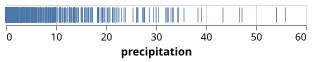

Open in the Vega editor: https://vega.github.io/editor/#/url/vega-lite/N4Igxg9gdgZglgcxALlANzgUwO4tJKAFzigFcJSBnAdTgBNCALFAZgAY2AacaYsiygAlMiRoVYcAvpO50AhoTl4QaOQBtSmSigDaoeYUwoQAJjYBGEwFoLN8yG4AHAE6YwcR3EXFoKLiEMAW0cAfUC5AA8USwA6AA5uINDAkhQAVm5sEjoUABYYgHZMzAVGTGdjOmc4AC8atSMZfQUjZFMLa1s2EwcQFzcPLwU4X2RzNhiATkTMYLDI6ImANhm5lKgUE3jM7LyYjJBsEqZy42c5VKaQA1b2yzsbFl7+909vEY3kCYSA2eSFsbmQqrZKpZAFGImHZQHLILYsYqlU5tc6XTjNQzGMz3Lq5Z6uV5DHyfMwxBG-NYA2JQimgz5pGIrQ67ZD5IqHY5lCooi4bK43LEdB5sNL4gZvYajIHkpLzKLIOJTEFhMFbH5ZGEoJYxcyIk7ckCovno64tQU48w2JZiwnvUZbA6y8Ly-K5ZXrTaQ6GwrY0o5Ig1GkD8s1tbGdS1sAo2wZ2z7+J0AiE0p2q7bMzVwsl6rlnXnBk0CsNCrpxGMS4l+d1UhN-FUk9Man055EgSikY0Y27h4WTctEj57GV150oSYxN20+vpb2sCctwP5kOY4sWqzjftx6LV+Xa3VTj1fRmz5AseccgN5tFd80R9f2JwE2OS+M7rU691g9cfjOwhn7-19WMdtO1NFc7jvSxNxfKsDwBPdP0+b92SbaIlQvIC2hAgsb1XSCnkfcUB1GWtKXlR0Ry-NUT2lBdgI7HCwO7EtLXMPFCNtGDWR-RMXXPVN42PX90mzDDcywqAIFwZdmLXcxRQ459K2QBlhzItD9wElArDPclUNPL0xNbShJOkwtQwgh5zGtRSK0HLMKPUsZgQPKjGxZA5APEttTMYotLNscxo1s4jPkVTSRwBXTENg-SGSZLzjN8mTbysssQq3MZxx+XjYK05ArGo4SVLoiSpL8iye0CvsMq4+TDNygqgQitY3PVFkgQSzkkvKlK8IeMxoOU8wz0c-55WTGKmp-fT4VKnzevM8CqstEwHz6J87NGNTxpQRUdunAy9JZRU-W6xdryY1LbBMHpauUhC4N3Fz8t9E98nVc6r1A-yVsKgiNqIzLSN2hVRPy5qTzPLrLx5S7fpYwr2MBzjlMVJlGvGKa3uK-95qDPqAtWhSUaU+zwrfMHplcz5XRPBlJ0Si6fsqxGTBs0mttp9NGsVamIZmlkPvxpcltku8TGCznQryyLnvZfLCsM-SgUZr62iqWp6kaMXrtW9LpeByntQVyjBISlkcaZ76KuWtmasNrjJZeuWx34s252p-T8k89XDVF3CiZ0tghvs6HKf2qbHrima-YJ3X+tsFh1peMmpR513kHHSd8ujlkzy9uOA6uxOI1DqVRoj9D8ui4qthQov4dZnFOjux3lJBuU9vBj3nJQy2hOtrCGMJqrOgB1Oudlpy2Pd1qGz9DzRKHtsR4TgLOmRyeZa+Sn6ox3vPKF5e-ew0eS06Ent6Np7ogLqagX7zMtkL2HV5Zu2W6tcvX1vsZHoFk-P880z7rzHjYKW18uITAOqOMY8UpoQnapmVSIsm6f1bjYA2UDlJFUxp3Q8R9n4uRXvHQO4C2AOxwfZB0e9IY0xQEgk8Ww1ZvzISXDe64Q73RofsPeeDe4myhmgj+4sbDWHMCnTaO9vhV35ofQe+dzykOLgjL+UEeFSirrAsERDYS0SMszW2YjujrgntIzKki56g0mgw7ijMOrKMbqI66Eit4WKdnwv+Qi7H0P0meACzjjGuPXFfDxHdKa2PyssGijY-aazqA0YJpd1wc2oenHKmcom91rrNWObDVHN0wUFH+0QISwJrFNOmxUzysMwv7dBJiJHYPCfZbUOdM4+JruhfSFNDE23PuoqhrSSLGxdvPT0i9MxshAWvchF9CrcPbmHSJGcJl92YT0oJgzMFrVKUeTJM8CFgiYcVCEvsCmNJCbdfZ6M97HIbMgv8WzLkuJSSYcxQNoHaOxu5TM99+nDzeZwkw7ivnDVVmM026zqn+K8Soq57ywngvsgQpMDVe5FX0u0kRySQVpJGZ8AxjUxqHW-ABJRdTvImUWvMr+kt9lovllNJWUzYR6VPnMjh4CTAtJRdtISjUum9xsIo6ZytT7JTAQskwwz+WCUOaDUlh4-Esgbm-GlZk6XjzsIysZLU6QaShvk+poDtWPHEfslMnTxmGoMl7JegTXl4qqiwR4eq-7UijiQtVszgWupsGC1GqL7mCsET6lBg9tnSpxG6kU+ztTyKcqcgWFLMzajOs6nZFq2AEvlX4LxQrbWHX8Hk9VpqpXmrYHGyBhLp6gz5iyx+mzy3Uq5WonVbA+XBtGZ6hBdiYl13hZy-1JY41yp7Z8cOf9s5TT0Z6T6WaY06o3JoolEwOnJoxesvO-ynFLqrW6yR+yRrFrgcK9ZWKl6LvqewjtFqNHLKlOOCp8pI4DrFbCDNIDK3crHWY-Zs6-79uiZ+kSHKNW-vvdW9cQa05hTDVuxVh1VXitba2O9RSH3IsnZsAFmN6H5X7THG91KoNYZg9ZW51iu5UymgCmOTrb2FIwQ+2t+as40bgVjD9Fs92kZ6lqv9sb1zdvg3OA+TllVfkHWW3F2bKMTvE3CVZ1r1nkuEYChpo6RODTXRJ1ZyHDxWxZDirTmHWMwb2fp5yr7u5Jrtahn0w6D3CZ1Tcmz+QDW0Z44AzZTHvIWZMW6j5HrMY41A3x5zAmDRmrcxa0FYXM7yXo8vJembTXtooyFnDymmV3x7pe5WA90NGIUyFvNuHd6eoETuwW4qIP1ISdrF1-6GWebWaDWem67U+LhTFgZy6EtianrZ0Nkm7W2Jjq-ZjiKAohaU6N52PWfMPPfGm2EsLo2HuDvskDmcgNEfeiQ7b8WYPJxPWeNTXW1tZieXOKlGGWMmNyLqmzQJlUAkbXY2Fpm4mueg697oSWZ4Xrtb9vdAXjJZcs0Dz5VWPt0LPWCXJSiodlaG2wIHcHRv5bGIO16fznPo-ojpzeNhcujfyBN2jh3MVE7QgNsqQnAffxszApH3nDyo+ITDWbZPA0QJB11gBvdm3FXyI1ttAusdYOF7RtaPFe5TePiToFrWcRA8WzIymZhvUbc9Gr9+Gvyerqfb-TGKbe7fbhRlwLz3rqvePTZuanrCPK+K7z+TmOndt3SYJT78pT0OcOsRgefP7dzaqk7+HeW97SanT0oW81mtJIU07nHOu+2IbtTz9lfqTeC-kvL7jov1kq+ITNyPMuneVeU30zGtdc4RueUz7ThfZclPe511bVTlGW291Wp3I2d5AiM1SJvHu2We0H2dp32vLETBD9x-Dh9NkR6e1Hksr29Pm-fDTlfhXest89KVwbQ-CpSI43jvXP3+-EKl9DmvhU-d1uq41D5R-DrvryRvjHF-Qt2dddxd8obclELlMtn9EsOs7MxhV91keM8k28gtHdCpKdR8JhoURdkcEMHUvdzMHdE4d869Rszxx8g94Dj8gERI7dN8oD2MqtZFPVJ86sDduJkDCCAod8R8b5MYy87Uf8B4IDvJU8dYACF8uJJd48c9v8k9MxOpZ9Wd2B9kpCase9DwK9YQOCt8cQ0g3s98jxA9ogQDw02CzMEUZc9Dgd2dC1ksWC7Uw9iFhC6CO8rDY9RtzBFQjDAQldy9Pd2V91+dXDA0T11CqQItTDjs-9z8zsrD0DeC7Cv9CFNlH9YsYcTErCSCs9Ld1DdFNlHs0jLChcgC-5P9l8wRd1nNaDCjgiu0S8qR318ogN-EC8FMrCJCIlmCkiKiT97VFCKM9Czd-d60fNqluk8D88tM4toNBir9GC95Gje4IdNsT4NV0jrpBjX9r9dcxjw1qCDICjSdgiRp6j5QTB9t1lmjj5qiji2jYNTjNgwcUMr1+NWjMdBj4jvlSjd

res3_1: scala.Unit | os.Path = ()

In [3]:
val stripPlot = VegaPlot.fromResource("strip_chart.vl.json")
stripPlot.plot(
  _.data.values := data.asJson
)

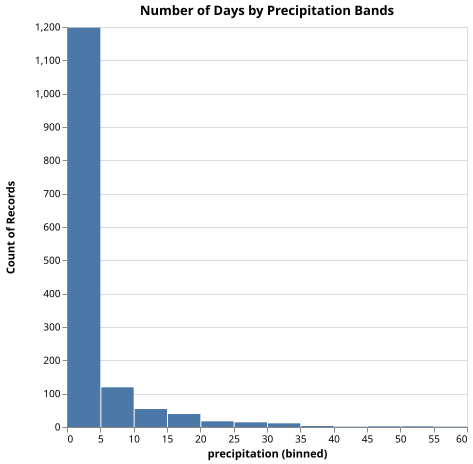

Open in the Vega editor: https://vega.github.io/editor/#/url/vega-lite/N4IgJAzgxgFgpgWwIYgFwhgF0wBwqgegIDc4BzJAOjIEtMYBXAI0poHsDp5kTykBaADZ04JAGyUAVhDYA7EABoQAEySYUqUMSSCGcCGgDaoVZjhoQAJgAMARkv87j24pA4ATnCg0cdNe3lUayUzBBwAfWQADzR7SgAOEMQIhBpAgFYlAHc05TQAFkoAdmy4NXh3C2V3GgAvWsFzAF8FEzVzdBt7Z0dLVw8vHz9MANjrSgBOJLDIpBjUW3GxaZS0tEsE7NyCykyQLLL6OEr0dyQ1lrazCy6HJ2sAZn7Pb191Ebk0ccSQUJS52K2YorSJrVBFSiWLayPKoDYPUrlY4WM4XVoqdo3Ox3WyOfLPQZvfyfOHjBG-ZKzeZxKEUmapDKUZb7baoQolfaHCoo87yS4Y66dbE9azpAmvYajBaUcl-KloeKTEEM9abFkwtASWyIo4nECovno0wdKzC+5icVDd5SjZ7OXRHb5ZVgja0nIauGQnXc068kD841Y7r3IqWokfQLBOn-eYQ2n2l1q92w+He5G+tFXE23EXxMOSklR+0AhZFykqz0-ZPrNN6iAMQ1ZoM4xwTfPWkmFWXlksTShO6OgjLQ2EPfu1nmZgXZs24xbt4mBbWDh2oLXOyNMkdoMcDg5IvUG-1GzFC4NzlxKAYSjuR5Ul9crsH8IHL6uodKUN9c9MgeuN6dmx6ewFwjL573mR8E0CF9gXVWEgSmTkDwsf9jybM8W1sJ4rxeK1F3AlcSztctnw2KtWSBcl911VCG3QwDMOA-FcMJAtAkKZdi3mQoB2gr4t3gtBP2on861kNgsgYwMmKcWwxVYm8CI-GUINiL8NzQfgx2o1kxzdMTUIkqSA1PU1zxfC1FPwsDPRI+kSyBDl+NQfhyO3D8J3QCBjOksyczk0NrPDKVFS4nt5h0zSgg8z9mRon0-180zBXMrC82C9jYj7H5uMIly3KTVk9gS38fMkvzUoCuc20y29Yk-eMIq019osKiiPSBeLDO85KTyq2c3OsUCpWw3Y1PBL0nxg1qhM9USUN6iqUpnCzLEvNw8JCkluwc+ZFV21ZAiiubFQMxb9T9FagKcSw+jq5SoOatc4Jc10PMKKsesuqcZLSnpLBwza2PqmKiP21TpvUt89ME0rDyu-rVpbSwWOBpTbMVZk8tLaL3rmz9vwuo9rtk3FLAU9GbNCjTwYVJUobZccCeZ+HJwAv7qrcqyqe2ji1RxxUkJc2b30+ryfo5-zBssILeaysGcYkZzSJg-H3yBPdvuqOoGmaJGbvJjL5dBss9s1V7VYE+LWXV76SYNsm3Nqk3lNly3zdQPs+Kt1AxyQsXxuQ2iMylgaLIeYaHtssdseeg7osfd9CYlh2MP+pwHg269qZJIFcue73E9p99-dTxH04CnERrzsd7Jjenhd9k73w2Dk2dDyrkd6Xoa7vOnUATxmnI8jZuoutDSYzu4gZzvn8ue2xeLxqbk8hju-3oqeq7xPuF89+TBJckrWS7CXJ8d6fHEpueFbNhuFjL4e4NbhmN4vyuzTuHnb9NibbCevSMEI8Cbny3pfHe1g5a-2UmSf+cVooQg6rCES5dfrS2DHcY2MDbLuQHosaKJ8PRtzQWHbu1g7guxwTaIOONbCzRckg0erN7YV0Ylfec0caH13lAsPBLllYeQWiHSWXcboOHoXvIIAt44M2PnDWGWtiZsM5l-F891Xa2XCp7Iex8PJUVIWI2SEjZ5bQVvQ5mOM4zRWXnNTWhjt5qKXlI20E1BHPxhh6McRMRFp3YTveSUj768OsYzJY+ikzaxqPURoRiOE-zMaDfOE1QkuRbrbEurD0HhzuBI6BiTlK2AhIdXhBDGa2NLiw5R2TyESOwQU2yEgfae3cWkt+rIwoOIgU4qhDSpTBNXK0326tT4v2+h-fxaibBSJKauJhz924ZIDlksh4i3LZz6YWGRB8Blgnme+CEJUVlxJ3ndKRWN-67MCHgteyzqmrOMW5UxINYETV0cMoqXi37jPAZ-TBbk0bULzvYgeQygH8z3LDI59yTlTJvps-uVippvU+bCJpXS-m5O5lIgxA8eEVlgp40cVSRHlRMt0-5ssgluI9kdLSIyvFgIeVfSw9SXkxyPs9MFdLXLhLmoUc6pK+qYp7pYXp7L+nbIfvi4BJdWTt3GcKyZwYHjOGpaC2mIs5VfJ8YlCZqiVW9y4SSJqLTaVDh3O0j0Kdg6JT8QamejhnkY36f-fGAiX7yqZbCw11hAUIv3g-RYnLwUW0WdauGxzHG+vhRKkkEgm6e3mVqolFtBV2pURgx11gElxs3Pih85qKxRlfgqieSqHVOscPkvNgbeFCzaiA0t3ro3ZrZS6ws8CQ08r5a-aFpLfnKuzeKjtx1u28KLozIhKZIkwtbVWzhmjRrjGaQ-VJvsk6KIxUOhdGza2PyLYWlWobKyxVnb4zNOSF0aKBUuPssySzvJPb21kEh01lQrVmhdzrc6BEnTjBBYSFERuEXqz9V7Hgvn9fui5A9k2+1FqMstF6ak3VVYE411yn50IYb7QDa8vrluWhSx1ADzmWNkYmnlT8166t-Par9kGilSP-YvK51shHnrA8RkVTH22-stXHT2MqYIvuIWMudJGF0joE3CFJyLfaEqEduytkHpmYcE-JguJ6GVopJRm1DslVXrRxZDQWciEPapnf2gzzKArGZvQGpm2ig3selOGmddGEaGYzsZn989FaL3db7MTM7CMDrs2aYz0HR11tXPJaK6SI3vrrIO1TxnY2xcCwfE6KK3QZOQ7Zn1jrLC5qywMxy-CN1WZ2KB38OsYn6148ZmtWXxb4NsR6jzlrwtFfnWp-jAXcV0L5Yw1exVvmSea87FxEJV2lLc5uj0FSo1Scg5HKRgGcasZPdOnYhX6OXvIaqrOOL9KXJXsgy1SiUOReDPkNVGnpQFohlRi1TNIUegkL1w7PmAoPYoequh3L3sVNhl5uid27gA-8+Y2hi8QFtN0jqlTjGAcxdkxV6ko2PlXc9BD7yaW0fXykYUITD8ds8puZRLjH6eM7r9Y4MrmOzMI81c3deGTx63eK3iatQPF6AJ5U20ZdXUtQ759YQbd8JrrXZye0JgcCebwl4z6wMmAtY-WItmr+OW1rYe4u29cXHLwZPQ2ua53bW-dV4bvdWXUz4Nwwr8b4nud9YN+ooJ8OcsWd28Bmd7ube88Z9hAXB8ROWoDqfCWDW9Yh8NxjzXXbyfvaS6OfXvHDeZcx--IX73FdLNRxBw3zOAudPwbl6r3WVI-e87bl8rXZPJPwW5sHxDi-kMN9LpJUrSlV5d-lr5dyef9cNxr8x4w3vxew3h5hQf68J6GlIiQqeZ+s5Pe45t1vF9j-WeHh+NgbGswyWLyHS+zlPa13CAfPKh6vwX+zC-sO-4Dzl8eu-VriU2bKkTkvALScN8g1Z8T0ylX468n898KYcVxgP9SkQcKwLcH9O8boHtSsZk+919p8wQt8JsUtIDPcqUr9MDHJb93sltYR2sN4GN-9WUD94D5dP9kdrNY9ol48oCJ9QYz58EttfYkCadH9O498NsntuC6EqtB8PIIChC1t0hHsl0tkXtAQi0cDdd0Ud8CDeM5DAdiClCD1ZkwR8MMkf9d9ZCnUcVFQ9CLEXMC9XdiUbsPctDd4nsW9xCFNN9dcycUDZJtCc9k9K8gD3s9t5pM8GdtCy8Zd8EzceVgiNgHDf9VdtCm9-CcZAY-ceUKDVR8DCdEjHAe9Xl8En0eVJ1S5QjVNtDOCCi6EyCKxcDh9vCM45CjcnNr8l4KMT0aM9IyjGMmj7dc9CjAiKx29KD14flciQIr9ZdOtq9ON4jxcQ8miX8qjnoKZx0KwSjRlsiVcFioN6DVxSsVClxqcvlpDtj+smi-DIjUjpiT0NjltMkLo49YlzjLI9jHJKd3s7jv9u

res4_1: scala.Unit | os.Path = ()

In [4]:
val histogram = VegaPlot.fromResource("histogram.vl.json")
histogram.plot(
  _.data.values := data.asJson,
  _.encoding.x.field := "precipitation",
  _.title := "Number of Days by Precipitation Bands",
  _.encoding.x.bin.step := 5
)

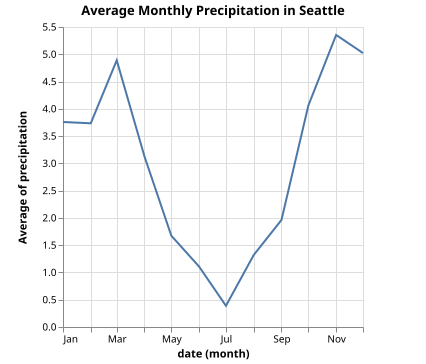

Open in the Vega editor: https://vega.github.io/editor/#/url/vega-lite/N4Igxg9gdgZglgcxALlANzgUwO4tJKAFzigFcJSBnAdTgBNCALFAZgAY2AacaYsiygAlMiRoVYcAvpO50AhoTl4QaOQBtSmSigDaoeYUwoQAJjYBGEwFoLN8yG4AHAE6YwcR3EXFoKLiEMAW0cAfUC5AA8USwA6AA5uINDAkhQAVm5sEjoUABYYgHZMzAVGTGdjOmc4AC8atSMZfQUjZFMLa1s2EwcQFzcPLwU4X2RzNhiATkTMYLDI6ImANhm5lKgUE3jM7LyYjJBsEqZy42c5VKaQA1b2yzsbFl7+909vEY3kCYSA2eSFsbmQqrZKpZAFGImHZQHLILYsYqlU5tc6XTjNQzGMz3Lq5Z6uV5DHyfMwxBG-NYA2JQimgz5pGIrQ67ZD5IqHY5lCooi4bK43LEdB5sNL4gZvYajIHkpLzKLIOJTEFhMFbH5ZGEoJYxcyIk7ckCovno64tQU48w2JZiwnvUZbA6y8Ly-K5ZXrTaQ6GwrY0o5Ig1GkD8s1tbGdS1sAo2wZ2z7+J0AiE0p2q7bMzVwsl6rlnXnBk0CsNCrpxGMS4l+d1UhN-FUk9Man055EgSikY0Y27h4WTctEj57GV150oSYxN20+vpb2sCctwP5kOY4sWqzjftx6LV+Xa3VTj1fRmz5AseccgN5tFd80R9f2JwE2OS+M7rU691g9cfjOwhn7-19WMdtO1NFc7jvSxNxfKsDwBPdP0+b92SbaIlQvIC2hAgsb1XSCnkfcUB1GWtKXlR0Ry-NUT2lBdgI7HCwO7EtLXMPFCNtGDWR-RMXXPVN42PX90mzDDcywqAIFwZdmLXcxRQ459K2QBlhzItD9wElArDPclUNPL0xNbShJOkwtQwgh5zGtRSK0HLMKPUsZgQPKjGxZA5APEttTMYotLNscxo1s4jPkVTSRwBXTENg-SGSZLzjN8mTbysssQq3MZxx+XjYK05ArGo4SVLoiSpL8iye0CvsMq4+TDNygqgQitY3PVFkgQSzkkvKlK8IeMxoOU8wz0c-55WTGKmp-fT4VKnzevM8CqstEwHz6J87NGNTxpQRUdunAy9JZRU-W6xdryY1LbBMHpauUhC4N3Fz8t9E98nVc6r1A-yVsKgiNqIzLSN2hVRPy5qTzPLrLx5S7fpYwr2MBzjlMVJlGvGKa3uK-95qDPqAtWhSUaU+zwrfMHplcz5XRPBlJ0Si6fsqxGTBs0mttp9NGsVamIZmlkPvxpcltku8TGCznQryyLnvZfLCsM-SgUZr62iqWp6kaMXrtW9LpeByntQVyjBISlkcaZ76KuWtmasNrjJZeuWx34s252p-T8k89XDVF3CiZ0tghvs6HKf2qbHrima-YJ3X+tsFh1peMmpR513kHHSd8ujlkzy9uOA6uxOI1DqVRoj9D8ui4qthQov4dZnFOjux3lJBuU9vBj3nJQy2hOtrCGMJqrOgB1Oudlpy2Pd1qGz9DzRKHtsR4TgLOmRyeZa+Sn6ox3vPKF5e-ew0eS06Ent6Np7ogLqagX7zMtkL2HV5Zu2W6tcvX1vsZHoFk-P880z7rzHjYKW18uITAOqOMY8UpoQnapmVSIsm6f1bjYA2UDlJFUxp3Q8R9n4uRXvHQO4C2AOxwfZB0e9IY0xQEgk8Ww1ZvzISXDe64Q73RofsPeeDe4myhmgj+4sbDWHMCnTaO9vhV35ofQe+dzykOLgjL+UEeFSirrAsERDYS0SMszW2YjujrgntIzKki56g0mgw7ijMOrKMbqI66Eit4WKdnwv+Qi7H0P0meACzjjGuPXFfDxHdKa2PyssGijY-aazqA0YJpd1wc2oenHKmcom91rrNWObDVHN0wUFH+0QISwJrFNOmxUzysMwv7dBJiJHYPCfZbUOdM4+JruhfSFNDE23PuoqhrSSLGxdvPT0i9MxshAWvchF9CrcPbmHSJGcJl92YT0oJgzMFrVKUeTJM8CFgiYcVCEvsCmNJCbdfZ6M97HIbMgv8WzLkuJSSYcxQNoHaOxu5TM99+nDzeZwkw7ivnDVVmM026zqn+K8Soq57ywngvsgQpMDVe5FX0u0kRySQVpJGZ8AxjUxqHW-ABJRdTvImUWvMr+kt9lovllNJWUzYR6VPnMjh4CTAtJRdtISjUum9xsIo6ZytT7JTAQskwwz+WCUOaDUlh4-Esgbm-GlZk6XjzsIysZLU6QaShvk+poDtWPHEfslMnTxmGoMl7JegTXl4qqiwR4eq-7UijiQtVszgWupsGC1GqL7mCsET6lBg9tnSpxG6kU+ztTyKcqcgWFLMzajOs6nZFq2AEvlX4LxQrbWHX8Hk9VpqpXmrYHGyBhLp6gz5iyx+mzy3Uq5WonVbA+XBtGZ6hBdiYl13hZy-1JY41yp7Z8cOf9s5TT0Z6T6WaY06o3JoolEwOnJoxesvO-ynFLqrW6yR+yRrFrgcK9ZWKl6LvqewjtFqNHLKlOOCp8pI4DrFbCDNIDK3crHWY-Zs6-79uiZ+kSHKNW-vvdW9cQa05hTDVuxVh1VXitba2O9RSH3IsnZsAFmN6H5X7THG91KoNYZg9ZW51iu5UymgCmOTrb2FIwQ+2t+as40bgVjD9Fs92kZ6lqv9sb1zdvg3OA+TllVfkHWW3F2bKMTvE3CVZ1r1nkuEYChpo6RODTXRJ1ZyHDxWxZDirTmHWMwb2fp5yr7u5Jrtahn0w6D3CZ1Tcmz+QDW0Z44AzZTHvIWZMW6j5HrMY41A3x5zAmDRmrcxa0FYXM7yXo8vJembTXtooyFnDymmV3x7pe5WA90NGIUyFvNuHd6eoETuwW4qIP1ISdrF1-6GWebWaDWem67U+LhTFgZy6EtianrZ0Nkm7W2Jjq-ZjiKAohaU6N52PWfMPPfGm2EsLo2HuDvskDmcgNEfeiQ7b8WYPJxPWeNTXW1tZieXOKlGGWMmNyLqmzQJlUAkbXY2Fpm4mueg697oSWZ4Xrtb9vdAXjJZcs0Dz5VWPt0LPWCXJSiodlaG2wIHcHRv5bGIO16fznPo-ojpzeNhcujfyBN2jh3MVE7QgNsqQnAffxszApH3nDyo+ITDWbZPA0QJB11gBvdm3FXyI1ttAusdYOF7RtaPFe5TePiToFrWcRA8WzIymZhvUbc9Gr9+Gvyerqfb-TGKbe7fbhRlwLz3rqvePTZuanrCPK+K7z+TmOndt3SYJT78pT0OcOsRgefP7dzaqk7+HeW97SanT0oW81mtJIU07nHOu+2IbtTz9lfqTeC-kvL7jov1kq+ITNyPMuneVeU30zGtdc4RueUz7ThfZclPe511bVTlGW291Wp3I2d5AiM1SJvHu2We0H2dp32vLETBD9x-Dh9NkR6e1Hksr29Pm-fDTlfhXest89KVwbQ-CpSI43jvXP3+-EKl9DmvhU-d1uq41D5R-DrvryRvjHF-Qt2dddxd8obclELlMtn9EsOs7MxhV91keM8k28gtHdCpKdR8JhoURdkcEMHUvdzMHdE4d869Rszxx8g94Dj8gERI7dN8oD2MqtZFPVJ86sDduJkDCCAod8R8b5MYy87Uf8B4IDvJU8dYACF8uJJd48c9v8k9MxOpZ9Wd2B9kpCase9DwK9YQOCt8cQ0g3s98jxA9ogQDw02CzMEUZc9Dgd2dC1ksWC7Uw9iFhC6CO8rDY9RtzBFQjDAQldy9Pd2V91+dXDA0T11CqQItTDjs-9z8zsrD0DeC7Cv9CFNlH9YsYcTErCSCs9Ld1DdFNlHs0jLChcgC-5P9l8wRd1nNaDCjgiu0S8qR318ogN-EC8FMrCJCIlmCkiKiT97VFCKM9Czd-d60fNqluk8D88tM4toNBir9GC95Gje4IdNsT4NV0jrpBjX9r9dcxjw1qCDICjSdgiRp6j5QTB9t1lmjj5qiji2jYNTjNgwcUMr1+NWjMdBj4jvlSjd

res5_1: scala.Unit | os.Path = ()

In [5]:
val linePlot = VegaPlot.fromResource("line.vl.json")
linePlot.plot(
  _.title := "Average Monthly Precipitation in Seattle",
  _.data.values := data.asJson,
  _.encoding.x.field := "date",
  _.encoding.x.timeUnit := "month",
  _.encoding.y.field := "precipitation",
)

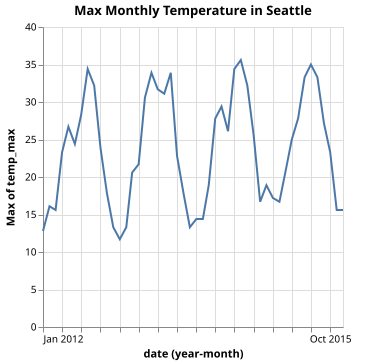

Open in the Vega editor: https://vega.github.io/editor/#/url/vega-lite/N4Igxg9gdgZglgcxALlANzgUwO4tJKAFzigFcJSBnAdTgBNCALFAZgAY2AacaYsiygAlMiRoVYcAvpO50AhoTl4QaOQBtSmSigDaoeYUwoQAJjYBGEwFoLN8yG4AHAE6YwcR3EXFoKLiEMAW0cAfUC5AA8USwA6AA5uINDAkhQAVm5sEjoUABYYgHZMzAVGTGdjOmc4AC8atSMZfQUjZFMLa1s2EwcQFzcPLwU4X2RzNhiATkTMYLDI6ImANhm5lKgUE3jM7LyYjJBsEqZy42c5VKaQA1b2yzsbFl7+909vEY3kCYSA2eSFsbmQqrZKpZAFGImHZQHLILYsYqlU5tc6XTjNQzGMz3Lq5Z6uV5DHyfMwxBG-NYA2JQimgz5pGIrQ67ZD5IqHY5lCooi4bK43LEdB5sNL4gZvYajIHkpLzKLIOJTEFhMFbH5ZGEoJYxcyIk7ckCovno64tQU48w2JZiwnvUZbA6y8Ly-K5ZXrTaQ6GwrY0o5Ig1GkD8s1tbGdS1sAo2wZ2z7+J0AiE0p2q7bMzVwsl6rlnXnBk0CsNCrpxGMS4l+d1UhN-FUk9Man055EgSikY0Y27h4WTctEj57GV150oSYxN20+vpb2sCctwP5kOY4sWqzjftx6LV+Xa3VTj1fRmz5AseccgN5tFd80R9f2JwE2OS+M7rU691g9cfjOwhn7-19WMdtO1NFc7jvSxNxfKsDwBPdP0+b92SbaIlQvIC2hAgsb1XSCnkfcUB1GWtKXlR0Ry-NUT2lBdgI7HCwO7EtLXMPFCNtGDWR-RMXXPVN42PX90mzDDcywqAIFwZdmLXcxRQ459K2QBlhzItD9wElArDPclUNPL0xNbShJOkwtQwgh5zGtRSK0HLMKPUsZgQPKjGxZA5APEttTMYotLNscxo1s4jPkVTSRwBXTENg-SGSZLzjN8mTbysssQq3MZxx+XjYK05ArGo4SVLoiSpL8iye0CvsMq4+TDNygqgQitY3PVFkgQSzkkvKlK8IeMxoOU8wz0c-55WTGKmp-fT4VKnzevM8CqstEwHz6J87NGNTxpQRUdunAy9JZRU-W6xdryY1LbBMHpauUhC4N3Fz8t9E98nVc6r1A-yVsKgiNqIzLSN2hVRPy5qTzPLrLx5S7fpYwr2MBzjlMVJlGvGKa3uK-95qDPqAtWhSUaU+zwrfMHplcz5XRPBlJ0Si6fsqxGTBs0mttp9NGsVamIZmlkPvxpcltku8TGCznQryyLnvZfLCsM-SgUZr62iqWp6kaMXrtW9LpeByntQVyjBISlkcaZ76KuWtmasNrjJZeuWx34s252p-T8k89XDVF3CiZ0tghvs6HKf2qbHrima-YJ3X+tsFh1peMmpR513kHHSd8ujlkzy9uOA6uxOI1DqVRoj9D8ui4qthQov4dZnFOjux3lJBuU9vBj3nJQy2hOtrCGMJqrOgB1Oudlpy2Pd1qGz9DzRKHtsR4TgLOmRyeZa+Sn6ox3vPKF5e-ew0eS06Ent6Np7ogLqagX7zMtkL2HV5Zu2W6tcvX1vsZHoFk-P880z7rzHjYKW18uITAOqOMY8UpoQnapmVSIsm6f1bjYA2UDlJFUxp3Q8R9n4uRXvHQO4C2AOxwfZB0e9IY0xQEgk8Ww1ZvzISXDe64Q73RofsPeeDe4myhmgj+4sbDWHMCnTaO9vhV35ofQe+dzykOLgjL+UEeFSirrAsERDYS0SMszW2YjujrgntIzKki56g0mgw7ijMOrKMbqI66Eit4WKdnwv+Qi7H0P0meACzjjGuPXFfDxHdKa2PyssGijY-aazqA0YJpd1wc2oenHKmcom91rrNWObDVHN0wUFH+0QISwJrFNOmxUzysMwv7dBJiJHYPCfZbUOdM4+JruhfSFNDE23PuoqhrSSLGxdvPT0i9MxshAWvchF9CrcPbmHSJGcJl92YT0oJgzMFrVKUeTJM8CFgiYcVCEvsCmNJCbdfZ6M97HIbMgv8WzLkuJSSYcxQNoHaOxu5TM99+nDzeZwkw7ivnDVVmM026zqn+K8Soq57ywngvsgQpMDVe5FX0u0kRySQVpJGZ8AxjUxqHW-ABJRdTvImUWvMr+kt9lovllNJWUzYR6VPnMjh4CTAtJRdtISjUum9xsIo6ZytT7JTAQskwwz+WCUOaDUlh4-Esgbm-GlZk6XjzsIysZLU6QaShvk+poDtWPHEfslMnTxmGoMl7JegTXl4qqiwR4eq-7UijiQtVszgWupsGC1GqL7mCsET6lBg9tnSpxG6kU+ztTyKcqcgWFLMzajOs6nZFq2AEvlX4LxQrbWHX8Hk9VpqpXmrYHGyBhLp6gz5iyx+mzy3Uq5WonVbA+XBtGZ6hBdiYl13hZy-1JY41yp7Z8cOf9s5TT0Z6T6WaY06o3JoolEwOnJoxesvO-ynFLqrW6yR+yRrFrgcK9ZWKl6LvqewjtFqNHLKlOOCp8pI4DrFbCDNIDK3crHWY-Zs6-79uiZ+kSHKNW-vvdW9cQa05hTDVuxVh1VXitba2O9RSH3IsnZsAFmN6H5X7THG91KoNYZg9ZW51iu5UymgCmOTrb2FIwQ+2t+as40bgVjD9Fs92kZ6lqv9sb1zdvg3OA+TllVfkHWW3F2bKMTvE3CVZ1r1nkuEYChpo6RODTXRJ1ZyHDxWxZDirTmHWMwb2fp5yr7u5Jrtahn0w6D3CZ1Tcmz+QDW0Z44AzZTHvIWZMW6j5HrMY41A3x5zAmDRmrcxa0FYXM7yXo8vJembTXtooyFnDymmV3x7pe5WA90NGIUyFvNuHd6eoETuwW4qIP1ISdrF1-6GWebWaDWem67U+LhTFgZy6EtianrZ0Nkm7W2Jjq-ZjiKAohaU6N52PWfMPPfGm2EsLo2HuDvskDmcgNEfeiQ7b8WYPJxPWeNTXW1tZieXOKlGGWMmNyLqmzQJlUAkbXY2Fpm4mueg697oSWZ4Xrtb9vdAXjJZcs0Dz5VWPt0LPWCXJSiodlaG2wIHcHRv5bGIO16fznPo-ojpzeNhcujfyBN2jh3MVE7QgNsqQnAffxszApH3nDyo+ITDWbZPA0QJB11gBvdm3FXyI1ttAusdYOF7RtaPFe5TePiToFrWcRA8WzIymZhvUbc9Gr9+Gvyerqfb-TGKbe7fbhRlwLz3rqvePTZuanrCPK+K7z+TmOndt3SYJT78pT0OcOsRgefP7dzaqk7+HeW97SanT0oW81mtJIU07nHOu+2IbtTz9lfqTeC-kvL7jov1kq+ITNyPMuneVeU30zGtdc4RueUz7ThfZclPe511bVTlGW291Wp3I2d5AiM1SJvHu2We0H2dp32vLETBD9x-Dh9NkR6e1Hksr29Pm-fDTlfhXest89KVwbQ-CpSI43jvXP3+-EKl9DmvhU-d1uq41D5R-DrvryRvjHF-Qt2dddxd8obclELlMtn9EsOs7MxhV91keM8k28gtHdCpKdR8JhoURdkcEMHUvdzMHdE4d869Rszxx8g94Dj8gERI7dN8oD2MqtZFPVJ86sDduJkDCCAod8R8b5MYy87Uf8B4IDvJU8dYACF8uJJd48c9v8k9MxOpZ9Wd2B9kpCase9DwK9YQOCt8cQ0g3s98jxA9ogQDw02CzMEUZc9Dgd2dC1ksWC7Uw9iFhC6CO8rDY9RtzBFQjDAQldy9Pd2V91+dXDA0T11CqQItTDjs-9z8zsrD0DeC7Cv9CFNlH9YsYcTErCSCs9Ld1DdFNlHs0jLChcgC-5P9l8wRd1nNaDCjgiu0S8qR318ogN-EC8FMrCJCIlmCkiKiT97VFCKM9Czd-d60fNqluk8D88tM4toNBir9GC95Gje4IdNsT4NV0jrpBjX9r9dcxjw1qCDICjSdgiRp6j5QTB9t1lmjj5qiji2jYNTjNgwcUMr1+NWjMdBj4jvlSjd

res6_1: scala.Unit | os.Path = ()

In [6]:
val linePlot = VegaPlot.fromResource("line.vl.json")
linePlot.plot(
  _.title := "Max Monthly Temperature in Seattle",
  _.data.values := data.asJson,
  _.encoding.x.field := "date",
  _.encoding.x.timeUnit := "yearmonth",
  _.encoding.y.field := "temp_max",
  _.encoding.y.aggregate := "max"
)

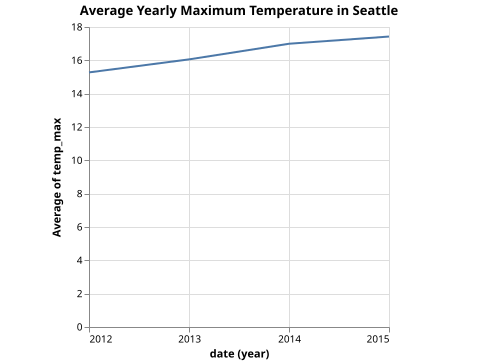

Open in the Vega editor: https://vega.github.io/editor/#/url/vega-lite/N4Igxg9gdgZglgcxALlANzgUwO4tJKAFzigFcJSBnAdTgBNCALFAZgAY2AacaYsiygAlMiRoVYcAvpO50AhoTl4QaOQBtSmSigDaoeYUwoQAJjYBGEwFoLN8yG4AHAE6YwcR3EXFoKLiEMAW0cAfUC5AA8USwA6AA5uINDAkhQAVm5sEjoUABYYgHZMzAVGTGdjOmc4AC8atSMZfQUjZFMLa1s2EwcQFzcPLwU4X2RzNhiATkTMYLDI6ImANhm5lKgUE3jM7LyYjJBsEqZy42c5VKaQA1b2yzsbFl7+909vEY3kCYSA2eSFsbmQqrZKpZAFGImHZQHLILYsYqlU5tc6XTjNQzGMz3Lq5Z6uV5DHyfMwxBG-NYA2JQimgz5pGIrQ67ZD5IqHY5lCooi4bK43LEdB5sNL4gZvYajIHkpLzKLIOJTEFhMFbH5ZGEoJYxcyIk7ckCovno64tQU48w2JZiwnvUZbA6y8Ly-K5ZXrTaQ6GwrY0o5Ig1GkD8s1tbGdS1sAo2wZ2z7+J0AiE0p2q7bMzVwsl6rlnXnBk0CsNCrpxGMS4l+d1UhN-FUk9Man055EgSikY0Y27h4WTctEj57GV150oSYxN20+vpb2sCctwP5kOY4sWqzjftx6LV+Xa3VTj1fRmz5AseccgN5tFd80R9f2JwE2OS+M7rU691g9cfjOwhn7-19WMdtO1NFc7jvSxNxfKsDwBPdP0+b92SbaIlQvIC2hAgsb1XSCnkfcUB1GWtKXlR0Ry-NUT2lBdgI7HCwO7EtLXMPFCNtGDWR-RMXXPVN42PX90mzDDcywqAIFwZdmLXcxRQ459K2QBlhzItD9wElArDPclUNPL0xNbShJOkwtQwgh5zGtRSK0HLMKPUsZgQPKjGxZA5APEttTMYotLNscxo1s4jPkVTSRwBXTENg-SGSZLzjN8mTbysssQq3MZxx+XjYK05ArGo4SVLoiSpL8iye0CvsMq4+TDNygqgQitY3PVFkgQSzkkvKlK8IeMxoOU8wz0c-55WTGKmp-fT4VKnzevM8CqstEwHz6J87NGNTxpQRUdunAy9JZRU-W6xdryY1LbBMHpauUhC4N3Fz8t9E98nVc6r1A-yVsKgiNqIzLSN2hVRPy5qTzPLrLx5S7fpYwr2MBzjlMVJlGvGKa3uK-95qDPqAtWhSUaU+zwrfMHplcz5XRPBlJ0Si6fsqxGTBs0mttp9NGsVamIZmlkPvxpcltku8TGCznQryyLnvZfLCsM-SgUZr62iqWp6kaMXrtW9LpeByntQVyjBISlkcaZ76KuWtmasNrjJZeuWx34s252p-T8k89XDVF3CiZ0tghvs6HKf2qbHrima-YJ3X+tsFh1peMmpR513kHHSd8ujlkzy9uOA6uxOI1DqVRoj9D8ui4qthQov4dZnFOjux3lJBuU9vBj3nJQy2hOtrCGMJqrOgB1Oudlpy2Pd1qGz9DzRKHtsR4TgLOmRyeZa+Sn6ox3vPKF5e-ew0eS06Ent6Np7ogLqagX7zMtkL2HV5Zu2W6tcvX1vsZHoFk-P880z7rzHjYKW18uITAOqOMY8UpoQnapmVSIsm6f1bjYA2UDlJFUxp3Q8R9n4uRXvHQO4C2AOxwfZB0e9IY0xQEgk8Ww1ZvzISXDe64Q73RofsPeeDe4myhmgj+4sbDWHMCnTaO9vhV35ofQe+dzykOLgjL+UEeFSirrAsERDYS0SMszW2YjujrgntIzKki56g0mgw7ijMOrKMbqI66Eit4WKdnwv+Qi7H0P0meACzjjGuPXFfDxHdKa2PyssGijY-aazqA0YJpd1wc2oenHKmcom91rrNWObDVHN0wUFH+0QISwJrFNOmxUzysMwv7dBJiJHYPCfZbUOdM4+JruhfSFNDE23PuoqhrSSLGxdvPT0i9MxshAWvchF9CrcPbmHSJGcJl92YT0oJgzMFrVKUeTJM8CFgiYcVCEvsCmNJCbdfZ6M97HIbMgv8WzLkuJSSYcxQNoHaOxu5TM99+nDzeZwkw7ivnDVVmM026zqn+K8Soq57ywngvsgQpMDVe5FX0u0kRySQVpJGZ8AxjUxqHW-ABJRdTvImUWvMr+kt9lovllNJWUzYR6VPnMjh4CTAtJRdtISjUum9xsIo6ZytT7JTAQskwwz+WCUOaDUlh4-Esgbm-GlZk6XjzsIysZLU6QaShvk+poDtWPHEfslMnTxmGoMl7JegTXl4qqiwR4eq-7UijiQtVszgWupsGC1GqL7mCsET6lBg9tnSpxG6kU+ztTyKcqcgWFLMzajOs6nZFq2AEvlX4LxQrbWHX8Hk9VpqpXmrYHGyBhLp6gz5iyx+mzy3Uq5WonVbA+XBtGZ6hBdiYl13hZy-1JY41yp7Z8cOf9s5TT0Z6T6WaY06o3JoolEwOnJoxesvO-ynFLqrW6yR+yRrFrgcK9ZWKl6LvqewjtFqNHLKlOOCp8pI4DrFbCDNIDK3crHWY-Zs6-79uiZ+kSHKNW-vvdW9cQa05hTDVuxVh1VXitba2O9RSH3IsnZsAFmN6H5X7THG91KoNYZg9ZW51iu5UymgCmOTrb2FIwQ+2t+as40bgVjD9Fs92kZ6lqv9sb1zdvg3OA+TllVfkHWW3F2bKMTvE3CVZ1r1nkuEYChpo6RODTXRJ1ZyHDxWxZDirTmHWMwb2fp5yr7u5Jrtahn0w6D3CZ1Tcmz+QDW0Z44AzZTHvIWZMW6j5HrMY41A3x5zAmDRmrcxa0FYXM7yXo8vJembTXtooyFnDymmV3x7pe5WA90NGIUyFvNuHd6eoETuwW4qIP1ISdrF1-6GWebWaDWem67U+LhTFgZy6EtianrZ0Nkm7W2Jjq-ZjiKAohaU6N52PWfMPPfGm2EsLo2HuDvskDmcgNEfeiQ7b8WYPJxPWeNTXW1tZieXOKlGGWMmNyLqmzQJlUAkbXY2Fpm4mueg697oSWZ4Xrtb9vdAXjJZcs0Dz5VWPt0LPWCXJSiodlaG2wIHcHRv5bGIO16fznPo-ojpzeNhcujfyBN2jh3MVE7QgNsqQnAffxszApH3nDyo+ITDWbZPA0QJB11gBvdm3FXyI1ttAusdYOF7RtaPFe5TePiToFrWcRA8WzIymZhvUbc9Gr9+Gvyerqfb-TGKbe7fbhRlwLz3rqvePTZuanrCPK+K7z+TmOndt3SYJT78pT0OcOsRgefP7dzaqk7+HeW97SanT0oW81mtJIU07nHOu+2IbtTz9lfqTeC-kvL7jov1kq+ITNyPMuneVeU30zGtdc4RueUz7ThfZclPe511bVTlGW291Wp3I2d5AiM1SJvHu2We0H2dp32vLETBD9x-Dh9NkR6e1Hksr29Pm-fDTlfhXest89KVwbQ-CpSI43jvXP3+-EKl9DmvhU-d1uq41D5R-DrvryRvjHF-Qt2dddxd8obclELlMtn9EsOs7MxhV91keM8k28gtHdCpKdR8JhoURdkcEMHUvdzMHdE4d869Rszxx8g94Dj8gERI7dN8oD2MqtZFPVJ86sDduJkDCCAod8R8b5MYy87Uf8B4IDvJU8dYACF8uJJd48c9v8k9MxOpZ9Wd2B9kpCase9DwK9YQOCt8cQ0g3s98jxA9ogQDw02CzMEUZc9Dgd2dC1ksWC7Uw9iFhC6CO8rDY9RtzBFQjDAQldy9Pd2V91+dXDA0T11CqQItTDjs-9z8zsrD0DeC7Cv9CFNlH9YsYcTErCSCs9Ld1DdFNlHs0jLChcgC-5P9l8wRd1nNaDCjgiu0S8qR318ogN-EC8FMrCJCIlmCkiKiT97VFCKM9Czd-d60fNqluk8D88tM4toNBir9GC95Gje4IdNsT4NV0jrpBjX9r9dcxjw1qCDICjSdgiRp6j5QTB9t1lmjj5qiji2jYNTjNgwcUMr1+NWjMdBj4jvlSjd

res7_1: scala.Unit | os.Path = ()

In [7]:
val linePlot = VegaPlot.fromResource("line.vl.json")
linePlot.plot(
  _.title := "Average Yearly Maximum Temperature in Seattle",
  _.data.values := data.asJson,
  _.encoding.x.field := "date",
  _.encoding.x.timeUnit := "year",
  _.encoding.y.field := "temp_max",
  _.encoding.y.aggregate := "average"
)

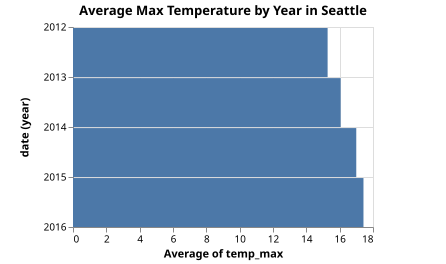

Open in the Vega editor: https://vega.github.io/editor/#/url/vega-lite/N4IgJAzgxgFgpgWwIYgFwhgF0wBwqgegIDc4BzJAOjIEtMYBXAI0poHsDp5kTykBaADZ04JAGyUAVhDYA7EABoQAEzjQATjRyZ289AEEABBBoIcguIaZJ1h2DcyGA7nRiHETOMtXLDypJhUiiA6mBZoIPqk6khklgCySAAehgAqiDhwMZgM6pZMAJ6GAJpwNoY0soYAymXY4UrwNGRYaABMAAwdSi7K9GgAzF1K-oFooMRIggxqaADaoKNwEZ0AjG38Haubq8E4eVBadAG6aN0hGQD6yElo65QAHEqYVwiVaACsPZXKaAAslAA7D06vB1BFlJoAF5Q8IAXwUiwCy3Qaw2W02bT2ByOgR0cjuHUoAE5nq9koTKGIyWZru9UG1Ht9ZL9UACviAnKCshEYu8EUiXistujth0Bti4IccMd8XoiU8LrSbndVkCaTg6XpAZQ2szWYyBiCAmDeUh+YiVMjhesdps-pLpbLTgyiUalZqVah7nqPVrPlT9f91ZzueD0Hz5AKrULUSK7R0Po7cScCd7KO6XsqKagHiSNf6GUzOT80BJVsb6DyI+ao5aljbRZsxMmZXiXYyOVnPTmAX8C289IzfS4We1dZXTTWLYKUSA0QnAa3nWnzt3rjmdb714Px4rRwaM5PqyBIyBow247aMR0Hsv26uBznVmvXvTGfvSwzj+GQBAGHWs6NgmxL3qmegApm5K3KgxKUP2fq7qgHIHoM8E-maM4xnOC4Yi+YFyncT4weWA70kS1IlmOqADOhoYmieZ4XtaV5NqsuxKPsUopoRqCvtmJGUBWiH0vwarCahyFCRh6D-oB2HAXhWKcTibbgWcxFltJIl6GJIaSWqpL0VWv5yee9YsfO8Z4RKKncWpvH8T2MFdm+ukfkG6bulyDGmQB5lAaxdqrA6dlOg+EHaTuvZ0Tu5GBlRrIfEexlTn+shsE4AUKUFeFJmFPEuslUECXcUVuWg-C0d5X60SOYYRBAGVZcxsZWde2yrC2BUOR2lCuaV6bAjplUeYlnwyelmXZZe7VsUuPUrnoebCdFMHVWR8qecllE+SZjXNTNlm4Z1d6LRFdxwYqa0aSNqD8GNkkoQ1smHa1OHWZ1oHnep3rJdu0GVeJm2jcWBkJXtaVNdN72KdsnQES6qy0QNzloFuIP3cD41Ft5L1TS1FltSdD0cSAXHhb9JVo7mKVxXoG043m9W+Zh8mzSTbTKeTqlLVpq2A6gEjDfT44jl+AL7vjTFEx9HUPbZPP2XzfGabT1OFtjkm0bt0u1kdxOfQ9oVK5TvF5pRN3ek5hbDtt2mQ4x+uw7l8P5abhVpitat5kZotsnRT2B3rWEc0bbTdR7vVppLPv5ndWsS2DIfs8d4cLVHKs216wuYw9E442qCGO7+kI0DC8Ky3DD1nZnF2q4hOa53dFGeXbqVO6Hafy2031179bQ6iLgtwQh-u0UZknspNMuBXNdpDIjaY63HGtIaROPJRJKcG3LTYDGTFOe3oarXSPsUVULDu1fHJds7vimikvJ8o3HfuX4zkmMsNd-TqnhvXnRNzI+0ctqNxgnmNe9I1Q-y-IyXWrNZL+RdvPDo6JFYgKzmrEKF9lTvgLkHPGiC-zIKrrldEJtMH12zs+HamMUJJyIftJB-896Yk2O7Khv0aEwWRvHf2MC2633xmZFBuF0SRy4Y5bBG8BH6S-M9YhoiyGoPRBnKRLo3TYLoXdHUn5qLFRns7FR4jNi1w0WmMaVsXz0KET-HeYjrLoj7hYoc-VsHY39nooRxcHEmKcWJDoz9xyow3Lwqxl9m7ayMV3ABQCxKH15tQ4sVtfb0IhjfXxxDZ45VUWJYBSTfoC0GpA2xhcUq-1PMYuepjkbBO9EXNWGM7p9k8o0juv4clh0AWJShhTeKdjVs3OREkb7b2ydU3JtTOH9M0U0gu-tW7lKlsQsuFdliOJ6V1epp95kAzwQzCpcCHZ+JqQE1Y6jZlpguXTQWNiWmB0yTE1hj8xLmKuXoCQY9BbDI-rfL83sOn302fE1YLiPm3Str8g5YtPIAnsUo0hZyekIx+rxNem4UmX0ETjRkk9TlTICW0RJytkln0GvcrxYMvw6kUcwqpsS2FoIegU0lv0LbYOzvg-RSVhETMZa8toGCIUN1SbcmFRYeVoXxYil55DjY7PaVCkM-tWk41fkCv+D95VtBmWy6R4D0YLMvo9L8XznnaryRHHZ4qaahKQnpUZ1FaJZPpdDQmyL4mD3qTwrSw8JX53Fs6yayjPXsLaO8-VLoV6Gqvv6z0okllTwISIt6-iUXgqjauLFg17XQOvtRBFbq01hvFDsH1QzyoSsTs6k5srLW4QGJiep+yabQoTYcyeCi630q6d3dBmxhVZrAdY9u-sok0pDUiwl14m0dD6cOyFdylnjvkQYiGBLukDsTPUiQ79BreITgW1kEgWa9smVuwdzYfXuNje2ws5wv76VTTDdN27LmLtFYLNJd09KwOot-KdcrUFzsjWbOZsbVg6MWRkgDt7KmhpnduzN4Hl4JStqPMpT6VnnoFblJt+E0VIyJN8g9xqJUb21sHflwHG0JJ2bReNYS-WY1NeunDaU+1xKvesHZcEMUQNtQ+2DJ6U1KJLUhnjQ7UN6Ew7G6Dl8k3dqYVDCTl6y0hXqRy2Nh6RlwufTRht1kCN6pk+0CeHiq0doDLtbtHGTzuqM7OsSkiRV5lIzTH949-nrvGbh2jxmxIfrM7BXBNNKWKZE2hezpk1P9p42B4+aFLaCzzbpJTcGi2cYvfFjTKGkvfh0+R6zWNj2DAtSCq9qL+7ovQ4LXTJqCFmuo-5pzA7iU2oE2gLz2KytFjpdlvDIGWX1IBMU8LXKT5rsPH5wbAXnNCorZBsdkXbNwZi41ad6mm1tAXSF31f1Maf27WeqGW3cs7dMwVg7fCoFuKDYeLLnd5vtdc5+m7ESKN9cgpNNZsINlvqq8FgrsdINqtXf+1ktENtasq2WiNnXOV1Ylc0oOMrWtw52-l0B7QdQeeY9bTGlGk6urm21q9i8iNpgU4NOT-sGHUXhRVwHZaD4MeKwTiLEq2NQ5a2TuHfxy1U6m-anMPWJVqskhIGHDKXv2mbcLpdFL71IUl2MoD5P52DptaL3hOLvM1VrbN57mvBfzqW9YldjWpVFmN35OXWud2K4Dil2nYXbbUuorszVBNTfXud1oyDni-mG8PAgjHLOzfA5x1+5XVnNbTeDCphz53uOO8SzHg7xL49IVR0nO3m2Hdm+x1g2NnQid9cZAXlhfvCM1Yg9YhrEqf1UdOybgX9HneGks+Nwsee4Ph-55H-JN7dd3As3dHRT7B-t+H3UgP2ijs+dZKTk8f3K6lsF5phfkGacleO8Gn3iH1Nb6u5nmROf6T98POjofm+XNaZz8+RmEP7Yy640yrf0eVbe8t5jNXAGzO9+qwGeP+Oa4WL+l81+0qQBkmWuYKOyRI+6EB-Cl8DOYesBJ+D0QSzuEgruKBd2LGuKBmEe9+HWO+Vs5eDyxcxyye9ufuXMFugsQqQmSEpSxBM+nSOWaegui2FBzB+ul8LeN8A2KeReCqzuP2kGE+Aij6xy7+3Bn+D0Z+P+RITGXoXUKqQhy+44nBwKw+1qzu0O2CMhkSieUkbeXBQ2uEvB3+ZKJhrB9IxOjOychmHeCO-BcevebBRycGohpc0I-2DBJe9cUh1ie+hYwhXuG6bhw+lO9eMcrBz4n2JW0BuYmBuWHwQuCR8ot61ighX2Tqomq+VhDuWRaCo+DhhBUka2h4-h+hpa5R0mBWIBeRdyweKOTWtaJRDRcB5Re2LR4BnOK2hR+mehsOLO5RKh1CVRWGtBGucO5Rb2+22CTeJW6B44PRNeixmwdh3CasLByBhYzhh4lhhemu5RoBMxkG7B-scm0SR+qeTK5RIR+x0hjhny5hE+lS

res8_1: scala.Unit | os.Path = ()

In [8]:
val barPlot = VegaPlot.fromResource("bar.vl.json")
barPlot.plot(
  _.data.values := data.asJson,
  _.encoding.x.field := "temp_max",
  _.encoding.x.aggregate := "average",
  _.encoding.y.field := "date",
  _.encoding.y.timeUnit := "year",
  _.height := 200,
  _.title := "Average Max Temperature by Year in Seattle"
)

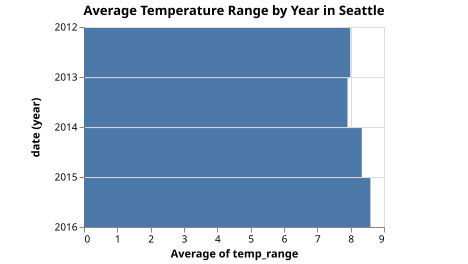

res9_2: scala.Unit | os.Path = ()

In [9]:
val dataWithRange = data.addColumn["temp_range", Double] {r => r.temp_max - r.temp_min}
Html(dataWithRange.take(5).html)
barPlot.plot(
  _.data.values := dataWithRange.asJson,
  _.encoding.x.field := "temp_range",
  _.encoding.x.aggregate := "average",
  _.encoding.y.field := "date",
  _.encoding.y.timeUnit := "year",
  _.height := 200,
  _.title := "Average Temperature Range by Year in Seattle"
)

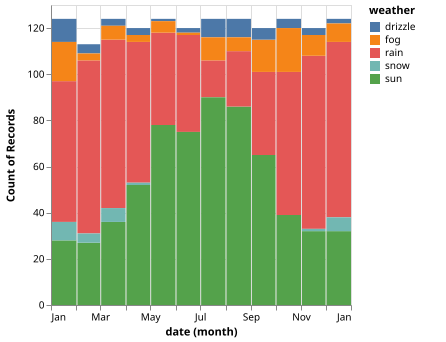

Open in the Vega editor: https://vega.github.io/editor/#/url/vega-lite/N4IgJAzgxgFgpgWwIYgFwhgF0wBwqgegIDc4BzJAOjIEtMYBXAI0poHsDp5kTykBaADZ04JAGyUAVhDYA7EABoQAEzjQATjRyZ289AEEABBBoIcguIaZJ1h2DcyGA7nRiHETOMtXLDypJhUiiA6mBZoIMHwNGRYaADMAAyJSi7K9AnJSv6BaKDESIIMamgA2qA5cBEATIkAjNX89U11wTjqcFBadAG6aCkhiDgA+sgAHmgNlAAcSphDozR6AKypS8poACyUAOypcAHw6hHKmgBeZ+EAvgoVAVXotQ0tTdVtHV04PTpyk4mUAE45gtxn9KGJgWZFnpqjM1rINqhtqsQE4DvQ4Md0OokEsQDc7vMavVGs1EvF3p1uoEfnp-rNBlDQag6nVdpCRgg8agdpRqvDEbD4vtDpiIji8QSVPdic8yZtKZ9vn1ULVKMLGZykBMWbD+ZroWhluCBVt2aj0Udxbj5FLKrLSXUmstFdTer8WeqOaNtWhpoDvVyYXDUes0BI6iKMViQBLbbdpUTHiSXokxK6vjSVbCUfMmb6kZRNoHuXrTaq+VGrdibfiE-bk3KnYkdhnlR6BnmtTrefqu4aKwyXAi0EKq2Ka5L6zLG46mtM21mO4GC3VOyDSyHh4LxzGIAx44SHiAnnPEgDF+69NsNf3mQCiyWVuX4o+LaKY3G60eHS815faUmFcdQjJ9+hNUMR1QV9i3faNrSnH9Zz-VolHaKlMyvfpgPDShIwNIM0H4Nl8O3I08N3CJ90PRNj1PP83jQj43UA1B13zECKII7liPNMjPSBODqxAajv1o39mjqCkmIw9s6Rw1Bcw3PR+FhIcw09DU0Q-KiDzEhsTxTSSFRkpUl2vLi7wLbZYLvbl-ghSDEWNLTLQnETZDYJx9JnQym2Il1TJYlUXIUkiwNQfhXy0jTX31bT4PQCBPO8u1fPoyT0yCzDWJzMLzTslS1PLFEEuE5KvJ8pM-LnOpW2yuS-UskEC2iiKBn441HLK9yKtS6dqoyp06gXBrzMmB8GSsnV2M5Hjiqco1KKSlKqroozhovMasJZY0+xanVePwwqiIW-i2W6ty91WtLBo21TEgAlUpMoJSOLQXsIqO8sxyE3qboG9b-OqVCQHQsydtvA6mqhpluTaxbUH9eKroQmiDKG1TGLB5icpVUCCILCQ9m44N4o07Yh1Ryd0fS+7qmknHZPGtiFP9WG5r0cLEdfS6dJptaJKdaoTKZiHWP9Rzpr+CKy0R41SOp2Na1uoG52qQKxeCj1-WO6GkYDUmzVgzq3x6z8VcBoXVKyrW8Y9Sm2cNk7PVIimtyVr9Vet6p6rtxrWcJziSZd1TK0RtkTaV04aAua4reQ5pqlG-2Wdmn1g-aiD+Ll820cFxPha21Odt9gr9YfWzlISQ3+ORZblcQ8TC6ix7ttY3mnY5gcCdNxX+cb2m7v8+JQfB7WuZDaXUEriLe9i2vPctpCateFono9F63u7JrBJdhGc74pem4xozSWx8f7fkoOYYitkScPvnEpEvTvcT0lGcvgP0+ZOobNl8OptXID1Em-VeiRSSiy-mnMKXUIqlXdsA5+oCE7gNJJraBO0f6rlfHvaunoH4aVhIJPOSVX6oIyqSW2mDWLYJ1HUAmLt74lQbiglelCmh+xoSqf43df5wKNjyLcGlQp-QtifOmcpSQp24R6Ba081zwJ+kfAeXsKFnyaMXWRwZt4Z0mNzF2vJ1JQVhFHVRy9m5oOIm3EuuVXphXkfg4mL4G5qPYRo1kG86RT31v6PBcMVjZwXmY5+bjLEcIaF4oCN8DZ8O5AgqCbIkHCTCafKRxFP64wDqyN809PqCP-hHM2x8h5qzXn-KJFZdHMmcYI7m-FXz91CRYtJ58AqVLoR9cOLsHLljZFTAeMc45VDARE6hWSWb9IUvk-eXpEawiaSklpki2l1UqXVOZCif7ckKQ04p5iJHD1WTIiZO0JBV3eqgWpsySEaV1q45ZRzylaNObQhS1z8G53dg-JWbDwkaNqJUvhBYjF3z4kQxeBzSkSUaCDDpPjLmKMEaCxGvJSolILlY6oF9XkqklmFbZwZjHOUhc0w5ZSIGqUyczLBXcAHEpriQ355D3HpJFusyO7zy4BONi+exYj86jIBRg3Fy4YkzM+cIqC5yHnkphTbdZmz9bVJ4vU4JrCAasrab7DpXKQ74LDuTKCyTeosv+Wyk5NKO4QWnh8nlkVemI22CjEBmrzXapeVanhCKd6KTBW7KCPzXWVSFXKeI69248K5Xre1arjVcVIS-aFidw0QMqftS5drOaMpKgmjFoaP5NGpeLKNMSpgZuzVc8FgbWFmtaUWpoUDRXXy2Tapx1aSVPyWXKlNzpKkSH8b6lFTCE0aQkC6slybwGpvGV6js-LbXcsrR1CFQbkFuvreSThuqYl+K+sw+ZKjkF1pWQ2xIlqS1ioUQInpQSTH8sTX8zdqbPWXr0J3GJs9BEJMFB7KFmKMrhv-JGze-wLlDu6e2gNiIYKyqnYB4iY9m2TFfPqzNS6BxnREX+ydAGjJAZxXOrmD5gU6nZlnbqY7AG-I3aerdUlKlfunje-BjqgEapDeosNxEm1EaalLfWw78FxsRNsNd3b4P4faSBmEuCwoGPwQI02Az12ca1Q2hhlT-Tgb0QbQdA45Pyzzf+gtGmuHIZnrk-WSLb2UfjSp8qtGnn0YvRPGuAnLkqpUmx1dcG8PcbqK+tzqppmQftd9HmfnTNbsBTJ9zoWpqSqNYiGVAqBbRfDXCuLmknb6cIq7ZR6KTNccLdiyp2wY2+ps8Jjto5jO4Yy1SndCi5a2eUQ501knuPsuy503aEUD7YYneVE9znMsir44HBRCMXZfPveJ9yqS6OZdnW+7CZbHH2vnlBG8DchmXBGSVhtOrsuOzLYUl2tS9kdfEV10rrmr6TCVYix1hjAHYaZcV9TMWguPdVLyHTv9CW4Wg7ytLg9-OFqSJUljlymOKfLGJqLR2t2j3WXFAl9K+UhIk5DxtEbbHPQXb452+DdlUZu4KlHmxXjNes1mgc5P42LM63jxINPySKuqauA9syYrM+R99jnvG1tTes69yVDKKws73KNilHOJui+2B5318P7VYcSThxzan3X47TPC0j+jmr2sG-erti3Hny+3b1sKjCauEJ23Mx9cuJIc4e9-BSINjeVvyXXerI27t69+x7mJtQ56jvvTL3Sgf2fWLp4ioT9q9082o193XsfPHZd+gohT9rfcQvN7dtnNPIm9eJ4iwzLslMF8F+nkvxbgt9bqF5nNTq9vnAO8Xnj8equw8rabmDtaY8l8V43233uBz5-vZ9hr1PiKreC-cstM320O5JZT9Lc+1nZamWW4HhYTZENr5ukv7vJk+t0y9OJegp8wdJbj6LJfg+TP+HlnBpP7U-rq4XqnQuHr9rbQr2e0rSu183ByW2cxpyy0JyvX1jDwKTNghRNVl2Hyxh710wZmAIHHI0PR-03z-wZnQOZC9zQ0rWTz2SK2PVQJ6xgIskNxZEr2ExXXvQ3wh0f1UlHz+zXAw1-gZ3y3IJr3AMt1dwVWy1fESyALy25FAKgj2mPzoygPM0m3pDChXy2wj1Ey1wtx7XASgLP1pTLTtyTydwhUoOEn23jgIOfx2l2zLT72wNrg0gunkMgNbnKywN-k2x93eyglYIgIpWWAJ20XAm53oV5yg3LFS0TX8IkkCLTTL1CJQw8PiTvV-TMO0JjziIby4P9ESJZFz28OSxrhxwyLZziJF2C13xazCxAI0LNDwLYJRziM4JD2m2SOfEPWQOjzKKaAXz+yb0T0rS-wrBKJQJ6JbCIILEwKkL0G21-WG1Z2iziP0LeTLRwJdi-QaSH3GOsNWLaOv1wjX1b2iOEMTkCOA1oPWwUQu3wUMy2PByfTo3OKQ2ULCnWLJ0QMdy6LI

res10_1: scala.Unit | os.Path = ()

In [10]:
val barPlot = VegaPlot.fromResource("colourbar.vl.json")
barPlot.plot(
  _.data.values := data.asJson,
  _.encoding.x := json"""{"field": "date", "type": "temporal", "timeUnit": "month"}""",
  _.encoding.y := json"""{"field": "weather", "type": "quantitative", "aggregate": "count"}""",
  _.encoding.color.field := "weather",
)

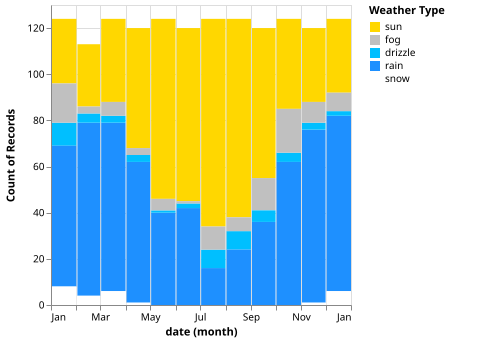

Open in the Vega editor: https://vega.github.io/editor/#/url/vega-lite/N4IgJAzgxgFgpgWwIYgFwhgF0wBwqgegIDc4BzJAOjIEtMYBXAI0poHsDp5kTykBaADZ04JAGyUAVhDYA7EABoQAEzjQATjRyZ289AEEABBBoIcguIaZJ1h2DcyGA7nRiHETOMtXLDypJhUiiA6mBZoIMHwNGRYaADMAAyJSi7K9AnJSv6BaKDESIIMamgA2qA5cBEATIkAjNX89U11wTjqcFBadAG6aCkhiDgA+sgAHmgNlAAcSphDozR6AKypS8poACyUAOypcAHw6hHKmgBeZ+EAvgoVAVXotQ0tTdVtHV04PTpyk4mUAE45gtxn9KGJgWZFnpqjM1rINqhtqsQE4DvQ4Md0OokEsQDc7vMavVGs1EvF3p1uoEfnp-rNBlDQag6nVdpCRgg8agdpRqvDEbD4vtDpiIji8QSVPdic8yZtKZ9vn1ULVKMLGZykBMWbD+ZroWhluCBVt2aj0Udxbj5FLKrLSXUmstFdTer8WeqOaNtWhpoDvVyYXDUes0BI6iKMViQBLbbdpUTHiSXokxK6vjSVbCUfMmb6kZRNoHuXrTaq+VGrdibfiE-bk3KnYkdhnlR6BnmtTrefqu4aKwyXAi0EKq2Ka5L6zLG46mtM21mO4GC3VOyDSyHh4LxzGIAx44SHiAnnPEgDF+69NsNf3mQCiyWVuX4o+LaKY3G60eHS815faUmFcdQjJ9+hNUMR1QV9i3faNrSnH9Zz-VolHaKlMyvfpgPDShIwNIM0H4Nl8O3I08N3CJ90PRNj1PP83jQj43UA1B13zECKII7liPNMjPSBODqxAajv1o39mjqCkmIw9s6Rw1Bcw3PR+FhIcw09DU0Q-KiDzEhsTxTSSFRkpUl2vLi7wLbZYLvbl-ghSDEWNLTLQnETZDYJx9JnQym2Il1TJYlUXIUkiwNQfhXy0jTX31bT4PQCBPO8u1fPoyT0yCzDWJzMLzTslS1PLFEEuE5KvJ8pM-LnOpW2yuS-UskEC2iiKBn441HLK9yKtS6dqoyp06gXBrzMmB8GSsnV2M5Hjiqco1KKSlKqroozhovMasJZY0+xanVePwwqiIW-i2W6ty91WtLBo21TEgAlUpMoJSOLQXsIqO8sxyE3qboG9b-OqVCQHQsydtvA6mqhpluTaxbUH9eKroQmiDKG1TGLB5icpVUCCILCQ9m44N4o07Yh1Ryd0fS+7qmknHZPGtiFP9WG5r0cLEdfS6dJptaJKdaoTKZiHWP9Rzpr+CKy0R41SOp2Na1uoG52qQKxeCj1-WO6GkYDUmzVgzq3x6z8VcBoXVKyrW8Y9Sm2cNk7PVIimtyVr9Vet6p6rtxrWcJziSZd1TK0RtkTaV04aAua4reQ5pqlG-2Wdmn1g-aiD+Ll820cFxPha21Odt9gr9YfWzlISQ3+ORZblcQ8TC6ix7ttY3mnY5gcCdNxX+cb2m7v8+JQfB7WuZDaXUEriLe9i2vPctpCateFono9F63u7JrBJdhGc74pem4xozSWx8f7fkoOYYitkScPvnEpEvTvcT0lGcvgP0+ZOobNl8OptXID1Em-VeiRSSiy-mnMKXUIqlXdsA5+oCE7gNJJraBO0f6rlfHvaunoH4aVhIJPOSVX6oIyqSW2mDWLYJ1HUAmLt74lQbiglelCmh+xoSqf43df5wKNjyLcGlQp-QtifOmcpSQp24R6Ba081zwJ+kfAeXsKFnyaMXWRwZt4Z0mNzF2vJ1JQVhFHVRy9m5oOIm3EuuVXphXkfg4mL4G5qPYRo1kG86RT31v6PBcMVjZwXmY5+bjLEcIaF4oCN8DZ8O5AgqCbIkHCTCafKRxFP64wDqyN809PqCP-hHM2x8h5qzXn-KJFZdHMmcYI7m-FXz91CRYtJ58AqVLoR9cOLsHLljZFTAeMc45VDARE6hWSWb9IUvk-eXpEawiaSklpki2l1UqXVOZCif7ckKQ04p5iJHD1WTIiZO0JBV3eqgWpsySEaV1q45ZRzylaNObQhS1z8G53dg-JWbDwkaNqJUvhBYjF3z4kQxeBzSkSUaCDDpPjLmKMEaCxGvJSolILlY6oF9XkqklmFbZwZjHOUhc0w5ZSIGqUyczLBXcAHEpriQ355D3HpJFusyO7zy4BONi+exYj86jIBRg3Fy4YkzM+cIqC5yHnkphTbdZmz9bVJ4vU4JrCAasrab7DpXKQ74LDuTKCyTeosv+Wyk5NKO4QWnh8nlkVemI22CjEBmrzXapeVanhCKd6KTBW7KCPzXWVSFXKeI69248K5Xre1arjVcVIS-aFidw0QMqftS5drOaMpKgmjFoaP5NGpeLKNMSpgZuzVc8FgbWFmtaUWpoUDRXXy2Tapx1aSVPyWXKlNzpKkSH8b6lFTCE0aQkC6slybwGpvGV6js-LbXcsrR1CFQbkFuvreSThuqYl+K+sw+ZKjkF1pWQ2xIlqS1ioUQInpQSTH8sTX8zdqbPWXr0J3GJs9BEJMFB7KFmKMrhv-JGze-wLlDu6e2gNiIYKyqnYB4iY9m2TFfPqzNS6BxnREX+ydAGjJAZxXOrmD5gU6nZlnbqY7AG-I3aerdUlKlfunje-BjqgEapDeosNxEm1EaalLfWw78FxsRNsNd3b4P4faSBmEuCwoGPwQI02Az12ca1Q2hhlT-Tgb0QbQdA45Pyzzf+gtGmuHIZnrk-WSLb2UfjSp8qtGnn0YvRPGuAnLkqpUmx1dcG8PcbqK+tzqppmQftd9HmfnTNbsBTJ9zoWpqSqNYiGVAqBbRfDXCuLmknb6cIq7ZR6KTNccLdiyp2wY2+ps8Jjto5jO4Yy1SndCi5a2eUQ501knuPsuy503aEUD7YYneVE9znMsir44HBRCMXZfPveJ9yqS6OZdnW+7CZbHH2vnlBG8DchmXBGSVhtOrsuOzLYUl2tS9kdfEV10rrmr6TCVYix1hjAHYaZcV9TMWguPdVLyHTv9CW4Wg7ytLg9-OFqSJUljlymOKfLGJqLR2t2j3WXFAl9K+UhIk5DxtEbbHPQXb452+DdlUZu4KlHmxXjNes1mgc5P42LM63jxINPySKuqauA9syYrM+R99jnvG1tTes69yVDKKws73KNilHOJui+2B5318P7VYcSThxzan3X47TPC0j+jmr2sG-erti3Hny+3b1sKjCauEJ23Mx9cuJIc4e9-BSINjeVvyXXerI27t69+x7mJtQ56jvvTL3Sgf2fWLp4ioT9q9082o193XsfPHZd+gohT9rfcQvN7dtnNPIm9eJ4iwzLslMF8F+nkvxbgt9bqF5nNTq9vnAO8Xnj8equw8rabmDtaY8l8V43233uBz5-vZ9hr1PiKreC-cstM320O5JZT9Lc+1nZamWW4HhYTZENr5ukv7vJk+t0y9OJegp8wdJbj6LJfg+TP+HlnBpP7U-rq4XqnQuHr9rbQr2e0rSu183ByW2cxpyy0JyvX1jDwKTNghRNVl2Hyxh710wZmAIHHI0PR-03z-wZnQOZC9zQ0rWTz2SK2PVQJ6xgIskNxZEr2ExXXvQ3wh0f1UlHz+zXAw1-gZ3y3IJr3AMt1dwVWy1fESyALy25FAKgj2mPzoygPM0m3pDChXy2wj1Ey1wtx7XASgLP1pTLTtyTydwhUoOEn23jgIOfx2l2zLT72wNrg0gunkMgNbnKywN-k2x93eyglYIgIpWWAJ20XAm53oV5yg3LFS0TX8IkkCLTTL1CJQw8PiTvV-TMO0JjziIby4P9ESJZFz28OSxrhxwyLZziJF2C13xazCxAI0LNDwLYJRziM4JD2m2SOfEPWQOjzKKaAXz+yb0T0rS-wrBKJQJ6JbCIILEwKkL0G21-WG1Z2iziP0LeTLRwJdi-QaSH3GOsNWLaOv1wjX1b2iOEMTkCOA1oPWwUQu3wUMy2PByfTo3OKQ2ULCnWLJ0QMdy6LI

res11_1: scala.Unit | os.Path = ()

In [11]:
val scale = json"""{
  "domain": ["sun", "fog", "drizzle", "rain", "snow"],
  "range": ["#FFD700", "#C0C0C0", "#00BFFF", "#1E90FF", "#FFFFFF"]
}
"""
// to debug chart
// os.write.over(os.pwd / "temp.json",
//   barPlot.build(
//     _.data.values := data.take(2).asJson,
//     _.encoding.x := json"""{"field": "date", "type": "temporal", "timeUnit": "month"}""",
//     _.encoding.y := json"""{"field": "weather", "type": "quantitative", "aggregate": "count"}""",
//     _.encoding.color := json"""{"field": "weather","legend": {"title": "Weather Type"}, "scale": $scale}""",
//   ).asJson.noSpaces
// )

barPlot.plot(
  _.data.values := data.asJson,
  _.encoding.x := json"""{"field": "date", "type": "temporal", "timeUnit": "month"}""",
  _.encoding.y := json"""{"field": "weather", "type": "quantitative", "aggregate": "count"}""",
  _.encoding.color := json"""{"field": "weather","legend": {"title": "Weather Type"}, "scale": $scale}""",
)

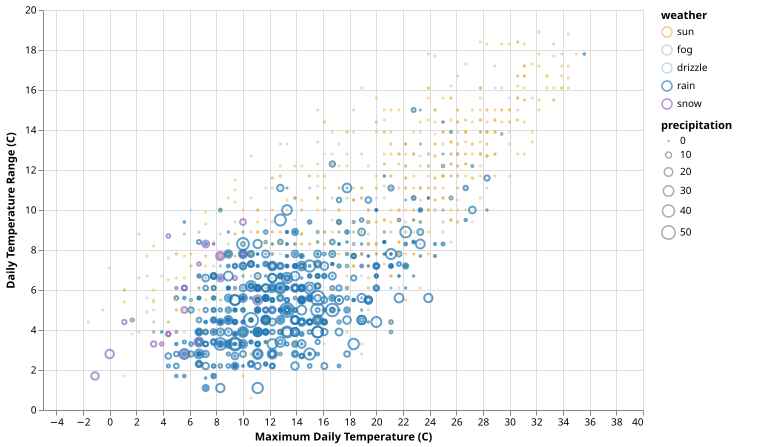

res12_1: scala.Unit | os.Path = ()

In [12]:
val scatter = VegaPlot.fromResource("scatter_seattle.vl.json")
scatter.plot(
  _.data.values := dataWithRange.asJson,
)

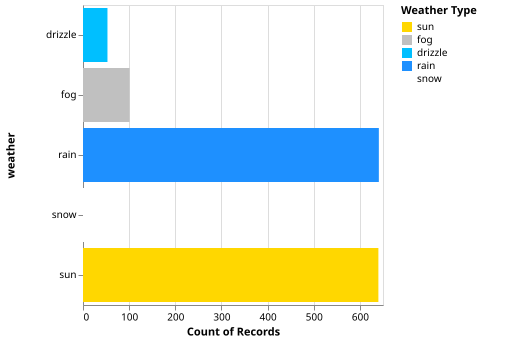

Open in the Vega editor: https://vega.github.io/editor/#/url/vega-lite/N4IgJAzgxgFgpgWwIYgFwhgF0wBwqgegIDc4BzJAOjIEtMYBXAI0poHsDp5kTykBaADZ04JAGyUAVhDYA7EABoQAEzjQATjRyZ289AEEABBBoIcguIaZJ1h2DcyGA7nRiHETOMtXLDypJhUiiA6mBZoIMHwNGRYaADMAAyJSi7K9AnJSv6BaKDESIIMamgA2qA5cBEATIkAjNX89U11wTjqcFBadAG6aCkhiDgA+sgAHmgNlAAcSphDozR6AKypS8poACyUAOypcAHw6hHKmgBeZ+EAvgoVAVXotQ0tTdVtHV04PTpyk4mUAE45gtxn9KGJgWZFnpqjM1rINqhtqsQE4DvQ4Md0OokEsQDc7vMavVGs1EvF3p1uoEfnp-rNBlDQag6nVdpCRgg8agdpRqvDEbD4vtDpiIji8QSVPdic8yZtKZ9vn1ULVKMLGZykBMWbD+ZroWhluCBVt2aj0Udxbj5FLKrLSXUmstFdTer8WeqOaNtWhpoDvVyYXDUes0BI6iKMViQBLbbdpUTHiSXokxK6vjSVbCUfMmb6kZRNoHuXrTaq+VGrdibfiE-bk3KnYkdhnlR6BnmtTrefqu4aKwyXAi0EKq2Ka5L6zLG46mtM21mO4GC3VOyDSyHh4LxzGIAx44SHiAnnPEgDF+69NsNf3mQCiyWVuX4o+LaKY3G60eHS815faUmFcdQjJ9+hNUMR1QV9i3faNrSnH9Zz-VolHaKlMyvfpgPDShIwNIM0H4Nl8O3I08N3CJ90PRNj1PP83jQj43UA1B13zECKII7liPNMjPSBODqxAajv1o39mjqCkmIw9s6Rw1Bcw3PR+FhIcw09DU0Q-KiDzEhsTxTSSFRkpUl2vLi7wLbZYLvbl-ghSDEWNLTLQnETZDYJx9JnQym2Il1TJYlUXIUkiwNQfhXy0jTX31bT4PQCBPO8u1fPoyT0yCzDWJzMLzTslS1PLFEEuE5KvJ8pM-LnOpW2yuS-UskEC2iiKBn441HLK9yKtS6dqoyp06gXBrzMmB8GSsnV2M5Hjiqco1KKSlKqroozhovMasJZY0+xanVePwwqiIW-i2W6ty91WtLBo21TEgAlUpMoJSOLQXsIqO8sxyE3qboG9b-OqVCQHQsydtvA6mqhpluTaxbUH9eKroQmiDKG1TGLB5icpVUCCILCQ9m44N4o07Yh1Ryd0fS+7qmknHZPGtiFP9WG5r0cLEdfS6dJptaJKdaoTKZiHWP9Rzpr+CKy0R41SOp2Na1uoG52qQKxeCj1-WO6GkYDUmzVgzq3x6z8VcBoXVKyrW8Y9Sm2cNk7PVIimtyVr9Vet6p6rtxrWcJziSZd1TK0RtkTaV04aAua4reQ5pqlG-2Wdmn1g-aiD+Ll820cFxPha21Odt9gr9YfWzlISQ3+ORZblcQ8TC6ix7ttY3mnY5gcCdNxX+cb2m7v8+JQfB7WuZDaXUEriLe9i2vPctpCateFono9F63u7JrBJdhGc74pem4xozSWx8f7fkoOYYitkScPvnEpEvTvcT0lGcvgP0+ZOobNl8OptXID1Em-VeiRSSiy-mnMKXUIqlXdsA5+oCE7gNJJraBO0f6rlfHvaunoH4aVhIJPOSVX6oIyqSW2mDWLYJ1HUAmLt74lQbiglelCmh+xoSqf43df5wKNjyLcGlQp-QtifOmcpSQp24R6Ba081zwJ+kfAeXsKFnyaMXWRwZt4Z0mNzF2vJ1JQVhFHVRy9m5oOIm3EuuVXphXkfg4mL4G5qPYRo1kG86RT31v6PBcMVjZwXmY5+bjLEcIaF4oCN8DZ8O5AgqCbIkHCTCafKRxFP64wDqyN809PqCP-hHM2x8h5qzXn-KJFZdHMmcYI7m-FXz91CRYtJ58AqVLoR9cOLsHLljZFTAeMc45VDARE6hWSWb9IUvk-eXpEawiaSklpki2l1UqXVOZCif7ckKQ04p5iJHD1WTIiZO0JBV3eqgWpsySEaV1q45ZRzylaNObQhS1z8G53dg-JWbDwkaNqJUvhBYjF3z4kQxeBzSkSUaCDDpPjLmKMEaCxGvJSolILlY6oF9XkqklmFbZwZjHOUhc0w5ZSIGqUyczLBXcAHEpriQ355D3HpJFusyO7zy4BONi+exYj86jIBRg3Fy4YkzM+cIqC5yHnkphTbdZmz9bVJ4vU4JrCAasrab7DpXKQ74LDuTKCyTeosv+Wyk5NKO4QWnh8nlkVemI22CjEBmrzXapeVanhCKd6KTBW7KCPzXWVSFXKeI69248K5Xre1arjVcVIS-aFidw0QMqftS5drOaMpKgmjFoaP5NGpeLKNMSpgZuzVc8FgbWFmtaUWpoUDRXXy2Tapx1aSVPyWXKlNzpKkSH8b6lFTCE0aQkC6slybwGpvGV6js-LbXcsrR1CFQbkFuvreSThuqYl+K+sw+ZKjkF1pWQ2xIlqS1ioUQInpQSTH8sTX8zdqbPWXr0J3GJs9BEJMFB7KFmKMrhv-JGze-wLlDu6e2gNiIYKyqnYB4iY9m2TFfPqzNS6BxnREX+ydAGjJAZxXOrmD5gU6nZlnbqY7AG-I3aerdUlKlfunje-BjqgEapDeosNxEm1EaalLfWw78FxsRNsNd3b4P4faSBmEuCwoGPwQI02Az12ca1Q2hhlT-Tgb0QbQdA45Pyzzf+gtGmuHIZnrk-WSLb2UfjSp8qtGnn0YvRPGuAnLkqpUmx1dcG8PcbqK+tzqppmQftd9HmfnTNbsBTJ9zoWpqSqNYiGVAqBbRfDXCuLmknb6cIq7ZR6KTNccLdiyp2wY2+ps8Jjto5jO4Yy1SndCi5a2eUQ501knuPsuy503aEUD7YYneVE9znMsir44HBRCMXZfPveJ9yqS6OZdnW+7CZbHH2vnlBG8DchmXBGSVhtOrsuOzLYUl2tS9kdfEV10rrmr6TCVYix1hjAHYaZcV9TMWguPdVLyHTv9CW4Wg7ytLg9-OFqSJUljlymOKfLGJqLR2t2j3WXFAl9K+UhIk5DxtEbbHPQXb452+DdlUZu4KlHmxXjNes1mgc5P42LM63jxINPySKuqauA9syYrM+R99jnvG1tTes69yVDKKws73KNilHOJui+2B5318P7VYcSThxzan3X47TPC0j+jmr2sG-erti3Hny+3b1sKjCauEJ23Mx9cuJIc4e9-BSINjeVvyXXerI27t69+x7mJtQ56jvvTL3Sgf2fWLp4ioT9q9082o193XsfPHZd+gohT9rfcQvN7dtnNPIm9eJ4iwzLslMF8F+nkvxbgt9bqF5nNTq9vnAO8Xnj8equw8rabmDtaY8l8V43233uBz5-vZ9hr1PiKreC-cstM320O5JZT9Lc+1nZamWW4HhYTZENr5ukv7vJk+t0y9OJegp8wdJbj6LJfg+TP+HlnBpP7U-rq4XqnQuHr9rbQr2e0rSu183ByW2cxpyy0JyvX1jDwKTNghRNVl2Hyxh710wZmAIHHI0PR-03z-wZnQOZC9zQ0rWTz2SK2PVQJ6xgIskNxZEr2ExXXvQ3wh0f1UlHz+zXAw1-gZ3y3IJr3AMt1dwVWy1fESyALy25FAKgj2mPzoygPM0m3pDChXy2wj1Ey1wtx7XASgLP1pTLTtyTydwhUoOEn23jgIOfx2l2zLT72wNrg0gunkMgNbnKywN-k2x93eyglYIgIpWWAJ20XAm53oV5yg3LFS0TX8IkkCLTTL1CJQw8PiTvV-TMO0JjziIby4P9ESJZFz28OSxrhxwyLZziJF2C13xazCxAI0LNDwLYJRziM4JD2m2SOfEPWQOjzKKaAXz+yb0T0rS-wrBKJQJ6JbCIILEwKkL0G21-WG1Z2iziP0LeTLRwJdi-QaSH3GOsNWLaOv1wjX1b2iOEMTkCOA1oPWwUQu3wUMy2PByfTo3OKQ2ULCnWLJ0QMdy6LI

res13: scala.Unit | os.Path = ()

In [13]:
barPlot.plot(
  _.data.values := data.asJson,
  _.encoding.x := json"""{"type": "quantitative", "aggregate": "count"}""",
  _.encoding.y := json"""{"field": "weather", "type": "nominal"}""",
  _.encoding.color := json"""{"field": "weather","legend": {"title": "Weather Type"}, "scale": $scale}""",
)

In this final chart I more or less cheated and copied the spec rather than building it up myself from first principles, because it's just a lot faster to do it that way. Also works IRL.

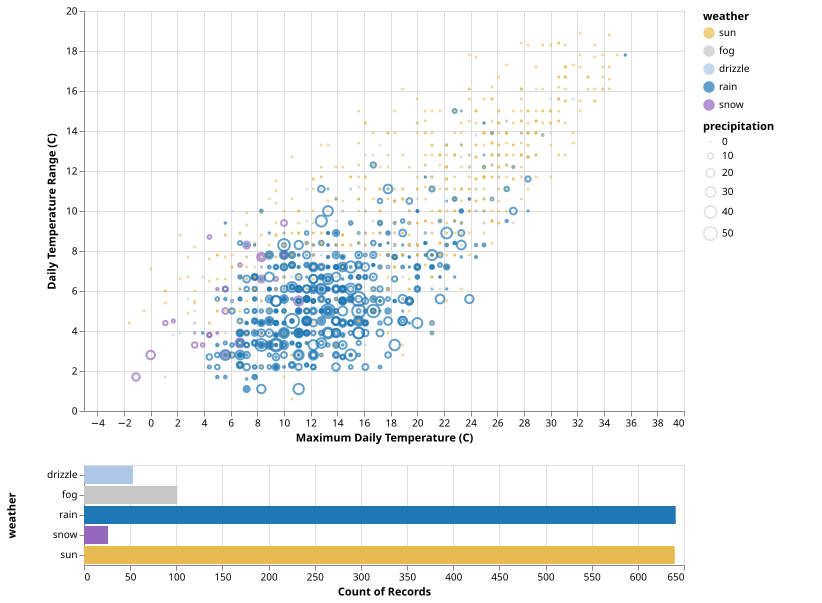

Open in the Vega editor: https://vega.github.io/editor/#/url/vega-lite/N4Igxg9gdgZglgcxALlANzgUwO4tJKAFzigFcJSBnAdTgBNCALFAZgAY2AacaYsiygAlMiRoVYcAvpO5oCYAIbjkAbVABbBQCcA1nhCEAngAdMKEMYglxMkJiiQ6JJKh4AbCFv0EnxaPuNtBXVzQK1ggH0AVgAWOjoANhiAdgBGAE4WOnSAIxY8kG54TDc6c2xMJUZML25KRTczVzoITRIUFRBKUihCkBgIJG46LTgALzHGvvD2uqgIXABdbnCoBCbOgGJMZJyFKIAmPs2wZNPT44VMU8wADmPUmGTdmOP0mITdssXbI1NzebqEgKNwgWxoEGkJogNyiQgIcKGMF1cZNUDFUqhLTXODGOCEJRwfx1BpokCrdYdVKcA4cH7cP7QgCOpAURHxhLQZlsAA99BiysgDJh1MYIpo+Qz8VMhQBZBQ8uDqUjqAAEABEFHA3IZVQAVEWmcKEUjY1UACgAwgBKPqM8wstnEAnELnIkBI1wC8yEQ0RClmKWEGUgTXa3UG0U1JSmzCqgBKbPWFptdpMzNZ7JdcDd0m41ThKBiHG4UGC0IwOAi+QO6QOByiewU6WyCVSyQibDtq0oAy0IVU+BBYFIbiU0PNdBj6hUAHJfaLxQrZ4tVQBaVVTk0z+d+oFQFe27gKSg+v0BsHLEDYehMFAJKScDTaPSue1CvZeWz2RzObwQDwvC9LBMSFCoqhqPp6hBMkWjaXpVC6Ho+gGIYQBGcZJkDcktV6OYFhAK8L0Q7Zdn2I5uBOM5qMua5kjuB4nheN4Pi+QjfnTAFWmBUFeX0BQEARTAEHHcxIB6cQGU4oVHSzTluW4T10RAwVr0qJhIKk-4hUBHiwV+Hs+wHNRwGHUdRKFSdpznBcxQlFd103azd0XfdDz6E8z0XC8ZGUtxfSA0AwmCUIgnUaI4kSFIMiyXJ8hYfSrxvBhmGQB82EkK8twUfQy3UaFstSd1gvUU9BxAPLoRKiL4iSNJMmyPICjqEprmUUB3xAawaghXjZCwbAys6StsGrHJa3rRsFGbVt207dirwAEnqapNHMMRCGMShkAAeh2rkRIAOgQfFGFIHJDqJHaVpFBR9uEhQ11hX19oSQ7UkOthDoAK0oYl0KUE9MEIMrQEKjowYskBaVSA41zYVJ4aK7hjGxMBcQ5PwEK4YVXIVFBYcO24GT3dpkCibgbygQUYkO5JKfU6ogPQ0YJimXyAd9cwYbhhH4Yoiw0Yx7N-GQVIvvSEm8b5MWvoSKW7LJg4icpkgacOim1Ig5mZl6Dmt2hHmkfhhKUaFvERexlXcbs-GxY++mbfFMnkkOg5VeplBlZYBntfMXXkUhrmhSNvm2FeM2cQtwlRdpQ6fadiUCeV93E7JqJDvl681aLOnfY0nXcMDznDYR3nEbYKI+lRqPMaJBCPoT2ylxl25DsltOEOV4ns89tL3vzpn-aL-WodDiuEmr8269jjWFZb3OYnn-cvbdj3BRTwfIKFAPR+D6Gy+Nthkin2vLZQHHm6T5BXdTq+letqmN-jrfC-aPfS9ho-7kj9Ho6xi+y87bi2Xg-HuT8vav3MN0PWT4S7c0PmHdIp8-4zwQrTJue47bpEOkvTuKBNYQOQCwXBUCd4jzgQbBBX8+bixQcLGODcgEyzetSfByA5br1YKQrWBdh7v0oWPRBiNUjI0FmfRhgDE521YaAhCa4PpsKIRnJRjNt5IVgUHT+5cFECxrqg8+HDmH3gHuwhRede6Cg+h3cCfChQwOLlQkOwiFGm3EQYyRRjpEy01vfeR3cuFixfrwoe9jkIf2oTo1IEd3EMIAcgWmbCr521pngvxF9M6BIzgnWxoSujzFwBE5xNCRFV1-nE+uBDgnJJloouRKA1wkJyTnYha8QnqMoAUxxQiSkKMnuU-+lTkDK18Vg2pFj0nIDXAEyxBCyH5IIkUg+vT2z0MGaLNuSSxncMwa5MmONlGZPaczTpizBH73Hgon+sT1kNxwT3GpUjJnTMfi0whaiTldKWZcjIay0EEwznfbZUy6lmJmUQj6WdckdK+ec7RxtaR-MMakEhozpYoFvvUkFpiiHe3macwpcLIkIrEfoipotdm21btU0mCEmmBLbqnaFb9NHwOKTo+sSLPGyO8SYx2kzN6zISY-D5-DWVOOWRytxZLblPOBW3SlzsG44paSQqForyECK0cSvmBwYkyv+cgNuWdHmyyxYKw5qi-aavFT0jlZSbmGs2cYo17csWpKyTw5lYrukXJcQcfpjrDG0wefKt17DQVEJDfM3eRL2UIpPgMw1l9gVvX5bShpFqWkfTwd6oUGE2YKW1fG3V1yDWGJTei-u6a9lWyhS0i1GqcJarZZKhFyCk2GIOK7GtVKUA4LSRm1pNiWm03eda5ttq-W9PYFy+JaqXUKqxTyy1MaKHFrbXzFgpLp7Iutqagdy6VV9xITYptsaN2h3LnOoZKK568tdR3SZ9KhXK0dnmydvr4VsF5no3dnjK19tdYqleQT30NqOR+hx3zEG82lf++JgGF5iw9ewrNfdsn4vCXGzdvN9UIaGUh6+qQM4mqHYQ0dwSoPYcvbB+GDry0AZdXep9Q6HaBOVmeid0GcNXvhoGxjiHmM8smexoV467EaK-Tq3miag0AZpVWkjRzJmu3AW8qj5712tr42wMtBHZ6hqU0R9OHGLEfovTpujbAO3yfiSM5joLVOvL7srXNWmW0Sr43QztniHMPsJkZxWCE02BJyR5qd364aiJvaLL6QXkNt1Y7Wqp9aT1eoi9Jkt0W-0SPiVsqtS72EUb7o3Ndnm7X81cbFhuOaXWYvYahiFGWJ2Wa83R6JNXV5oqA6FiNx7BQkKtZJtrlWf0KIYwZ7G9W2mTM4UKj64Cm0Fqwll3DfSutBIS9fBrz6qMQeG3k0b07f0KLk4J29rsQPAJM+gr1qqWsje0+1mh0X9N5aGW9QdVa+t7ZHX3Z1xyfUwdewo2zF24sut+0O9D6t31Np47R0HiLfPzpm9tsmYncXhos89sbcMDg7o+3F-dwKQHsLU4E12Emjt45O1VzlqOhnGuY7d1e6mMM48yyD07Bx4PE+mw+orAqXODa59xmjVnkf4YFwTOrD7ocpeFbmh7NP1HHai9MybsuvGmt2zD0XJj3Otbp5rgNm2ysPp60qhpkaHvG8kwStbfHu2baIzIiZQ6XlMtVVhyLMnpnvY8fOlTqbPdK-hpByjTKEewqR7z8HU2Mnbbttb0Ddu+7w+43HqXcGkZu6h6Y0TA3uGHY6ZLl7eef2baBT98PwXuH-cFCo8r-uS0sBNgXgLgrJl9aIVnx3Fexsd-Dl3014tQ9K77xp9VJuKv07YCP7XwfPvhr16TpXGfBRvRj3Ptvm6R8CaTxw+9prFcN68djgfeSnc85NvDc7x-3fUuSxf8x4HXPmYR0PhfI+g-ksF3H1IyxXm2xzVxOR-2-RH0Tx1wXQfUPWKzMyWz32d0QQ7x8zs1vS+m+yA31ynxL1aQd1p3nygIUSJxX1FjvV7WQ3Pxt2GUN3JhFRQLv0X10QtxwWu2pRA32Sjz7h33xRz0r3vxRU2wQNNWAPYVAI03C2zzOXj2EJlwoIQhZwfUp36yUUo2v3V1Nx1XQOXwAK9lPUcyL3I14ObyYMd0EOHw2yZw2R4VNSSyxSMPExxW514zQLO1EPsLJzZxPzSzF2QMsLkNz2EP-1lVaTIyrTTzJkj38NXi0JZVQJoXQJgKUMgVUNmy9y31YFbySLzxR0wIpUn1wI3wv1hyN1yJYI70Jwt0UyA0cPULM3AOB3cOSOmVyzSOFQKyA3J2Lw-2fjL0SKqOmX506Of2TkyKVykM-0CJv0gN0OmUUIMN1zJ2iLpX205130H331DmqP0PCPGLFhfRFx90-wSJaPkNYPN1sMALJxmV7wIIwXmRW3ZlaPyMfx12jQC1QweP

res14_1: scala.Unit | os.Path = ()

In [14]:
// This is essentially cheating, but it works if you know the spec you want...
val finalChart = VegaPlot.fromResource("final.vl.json")
finalChart.plot(
  _.datasets.data1 := data.asJson,
)